In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import os, numpy as np
import einops
os.chdir("/home/tanpham/BadFedBacktime")
from dataset import load_raw_data
from easydict import EasyDict as edict
import yaml
config = yaml.load(open("/home/tanpham/BadFedBacktime/configs/surrogate_config/default_config.yaml", 'r'), Loader=yaml.FullLoader)

/home/tanpham/BadFedBacktime/backtime/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Visualize backdoor pattern function

In [4]:
def visualize_backdoor_pattern(global_atk_prediction, 
                               global_atk_label,
                               global_clean_label, 
                               global_clean_prediction, 
                               local_atk_prediction, 
                               local_clean_prediction,
                               global_local_atk_prediction,
                               global_local_clean_prediction,
                               title,
                               mode='atk'):
    
    global_atk_prediction_mean  = global_atk_prediction.mean(axis=1).tolist()
    global_atk_label_mean = global_atk_label.mean(axis=1).tolist()
    
    global_clean_label_mean = global_clean_label.mean(axis=1).tolist()
    global_clean_prediction_mean = global_clean_prediction.mean(axis=1).tolist()

    local_atk_prediction_mean = local_atk_prediction.mean(axis=1).tolist()
    local_clean_prediction_mean = local_clean_prediction.mean(axis=1).tolist()
    
    global_local_atk_prediction_mean = global_local_atk_prediction.mean(axis=1).tolist()
    global_local_clean_prediction_mean = global_local_clean_prediction.mean(axis=1).tolist()
    
    
    global_atk_prediction_std = global_atk_prediction.std(axis=1).tolist()
    global_clean_prediction_std = global_clean_prediction.std(axis=1).tolist()
    global_clean_label_std = global_clean_label.std(axis=1).tolist()
    local_atk_prediction_std = local_atk_prediction.std(axis=1).tolist()
    local_clean_prediction_std = local_clean_prediction.std(axis=1).tolist()
    global_local_atk_prediction_std = global_local_atk_prediction.std(axis=1).tolist()
    global_local_clean_prediction_std = global_local_clean_prediction.std(axis=1).tolist()

    import numpy as np
    import matplotlib.pyplot as plt

    def moving_avg(arr, window):
        arr = np.asarray(arr)
        if window <= 1:
            return arr
        # simple convolution moving average
        kernel = np.ones(window) / window
        return np.convolve(arr, kernel, mode='valid')

    window = 100  # smooth over 50 timesteps (tune)
    stride = 10   # plot every 10th smoothed point (tune)

    global_atk_prediction_smooth  = moving_avg(global_atk_prediction_mean, window)
    global_atk_label_smooth = moving_avg(global_atk_label_mean, window)
    global_atk_prediction_std_smooth = moving_avg(global_atk_prediction_std, window)
    global_clean_prediction_smooth = moving_avg(global_clean_prediction_mean, window)
    global_clean_prediction_std_smooth = moving_avg(global_clean_prediction_std, window)
    global_clean_label_smooth = moving_avg(global_clean_label_mean, window)
    global_clean_label_std_smooth = moving_avg(global_clean_label_std, window)
    local_atk_prediction_smooth = moving_avg(local_atk_prediction_mean, window)
    local_atk_prediction_std_smooth = moving_avg(local_atk_prediction_std, window)
    local_clean_prediction_smooth = moving_avg(local_clean_prediction_mean, window)
    local_clean_prediction_std_smooth = moving_avg(local_clean_prediction_std, window)
    global_local_atk_prediction_smooth = moving_avg(global_local_atk_prediction_mean, window)
    global_local_atk_prediction_std_smooth = moving_avg(global_local_atk_prediction_std, window)
    global_local_clean_prediction_smooth = moving_avg(global_local_clean_prediction_mean, window)
    global_local_clean_prediction_std_smooth = moving_avg(global_local_clean_prediction_std, window)

    
    # plt.figure(figsize=(15, 8))
    import seaborn as sns
    palette = sns.color_palette()
    plt.title(title)
    if mode == 'atk':
        sns.lineplot(y=global_atk_prediction_smooth, x=np.arange(len(global_atk_prediction_smooth)), label='BACKTIME atk (original)', color=palette[0], linestyle='-')
        sns.lineplot(y=global_atk_label_smooth, x=np.arange(len(global_atk_label_smooth)), label='Clean prediction', color=palette[1])
        sns.lineplot(y=local_atk_prediction_smooth, x=np.arange(len(local_atk_prediction_smooth)), label='MSAT atk', color=palette[2], linestyle='--')
        sns.lineplot(y=global_atk_label_smooth, x=np.arange(len(global_atk_label_smooth)), label='Label', color=palette[3])
        sns.lineplot(y=global_local_atk_prediction_smooth, x=np.arange(len(global_local_atk_prediction_smooth)), label='HSAT atk', color=palette[4], linestyle='--')
        plt.legend()
        plt.xlabel('Timestamps')
        plt.ylabel('Value')
        plt.show()
    elif mode == 'clean':
        sns.lineplot(y=global_clean_prediction_smooth, x=np.arange(len(global_clean_prediction_smooth)), label='BACKTIME clean (original)', color=palette[0], linestyle='-')
        sns.lineplot(y=local_clean_prediction_smooth, x=np.arange(len(local_clean_prediction_smooth)), label='MSAT clean', color=palette[2], linestyle='--')
        sns.lineplot(y=global_clean_label_smooth, x=np.arange(len(global_clean_label_smooth)), label='Label', color=palette[3])
        sns.lineplot(y=global_local_clean_prediction_smooth, x=np.arange(len(global_local_clean_prediction_smooth)), label='HSAT clean', color=palette[4], linestyle='--')
        plt.legend()
        plt.show()

In [18]:
import pandas as pd
clean_mae_global = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/CLEAN_PEMS03_Autoformer_Autoformer/CLEAN_PEMS03_surrogate=Autoformer_model=Autoformer_warmup=50_test_metrics.csv")

print(clean_mae_global[clean_mae_global['phase'] == 'victim']['clean_mae'].tolist()[-1], clean_mae_global[clean_mae_global['phase'] == 'victim']['attacked_mae'].tolist()[-1])

17.351381301879883 14.136992454528809


In [19]:
import pandas as pd
clean_mae_global = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/CLEAN_PEMS03_FEDformer_FEDformer/CLEAN_PEMS03_surrogate=FEDformer_model=FEDformer_warmup=10_test_metrics.csv")

print(clean_mae_global[clean_mae_global['phase'] == 'victim']['clean_mae'].tolist()[-1], clean_mae_global[clean_mae_global['phase'] == 'victim']['attacked_mae'].tolist()[-1])

16.41112518310547 11.22443389892578


In [20]:
import pandas as pd

clean_mae_global = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/CLEAN_PEMS04_TimesNet_TimesNet/CLEAN_PEMS04_surrogate=TimesNet_model=TimesNet_warmup=50_test_metrics.csv")
print(clean_mae_global[clean_mae_global['phase'] == 'victim']['clean_mae'].tolist()[-1], clean_mae_global[clean_mae_global['phase'] == 'victim']['attacked_mae'].tolist()[-1])

27.327930450439453 25.519678115844727


# electricity

## TimesNet

In [7]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_TimesNet_TimesNet/electricity_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrCNN1D_TimesNet_TimesNet/electricity_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrHybridGCN_TimesNet_TimesNet/electricity_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])



565.2781982421875 933.19921875
613.6260375976562 758.28759765625
889.7362060546875 554.125732421875


## Autoformer

In [8]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrCNN1D_Autoformer_Autoformer/electricity_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrHybridGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

525.522216796875 949.1560668945312
527.8591918945312 1313.0888671875
573.2696533203125 600.5750122070312


(5238, 7, 96) (5238, 12, 321)
(5238, 7, 96) (5238, 12, 321)
(5238, 672) (5238, 3852)
(5238, 672) (5238, 3852)
(5238, 672) (5238, 3852)
(5238, 672) (5238, 3852)


AttributeError: module 'matplotlib.pyplot' has no attribute 'xaxis'

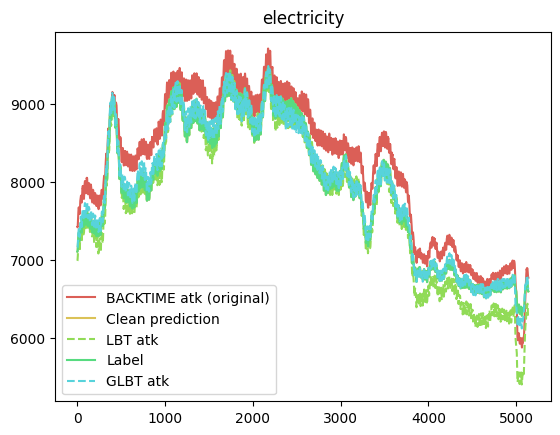

In [9]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_140.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_140.npy")

global_atk_targets = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_140.npy")

global_clean_targets = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_targets_epoch99_victim_140.npy")

local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrCNN1D_Autoformer_Autoformer/electricity_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_179.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrCNN1D_Autoformer_Autoformer/electricity_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_179.npy")

global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrHybridGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_180.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrHybridGCN_Autoformer_Autoformer/electricity_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_180.npy")

print(global_atk_prediction.shape, global_clean_prediction.shape)
# print(local_atk_prediction.shape, local_clean_prediction.shape)
# print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")
global_clean_targets = einops.rearrange(global_clean_targets, "b c t -> b (c t)")
global_atk_targets = einops.rearrange(global_atk_targets, "b c t -> b (c t)")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="electricity",
                           mode = 'atk')

## Fedformer

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrGCN_FEDformer_FEDformer/electricity_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrCNN1D_FEDformer_FEDformer/electricity_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/electricity_cone_TgrHybridGCN_FEDformer_FEDformer/electricity_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])



530.973388671875 1463.3941650390625
510.38031005859375 417.2593688964844
466.5972290039063 668.4026489257812


# ETTm1Time

In [ ]:
data_path = "/home/tanpham/BadFedBacktime/data/all_datasets/ETT-small/ETTm1.csv"
df = pd.read_csv(data_path)
df

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
...,...,...,...,...,...,...,...,...
69675,2018-06-26 18:45:00,9.310,3.550,5.437,1.670,3.868,1.462,9.567000
69676,2018-06-26 19:00:00,10.114,3.550,6.183,1.564,3.716,1.462,9.567000
69677,2018-06-26 19:15:00,10.784,3.349,7.000,1.635,3.746,1.432,9.426000
69678,2018-06-26 19:30:00,11.655,3.617,7.533,1.706,4.173,1.523,9.426000


## Autoformer

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrGCN_Autoformer_Autoformer/ETTm1Time_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrCNN1D_Autoformer_Autoformer/ETTm1Time_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrHybridGCN_Autoformer_Autoformer/ETTm1Time_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.1759326457977295 0.7801755666732788
1.1871049404144287 1.0858725309371948
1.1812453269958496 0.7914307713508606


# WeatherTime

## Autoformer

In [ ]:
import pandas as pd

global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrGCN_Autoformer_Autoformer/WeatherTime_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrCNN1D_Autoformer_Autoformer/WeatherTime_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrHybridGCN_Autoformer_Autoformer/WeatherTime_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

9.06441593170166 8.227821350097656
8.844453811645508 7.144209384918213
9.300963401794434 8.201526641845703


## Fedformer

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrGCN_FEDformer_FEDformer/WeatherTime_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrCNN1D_FEDformer_FEDformer/WeatherTime_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrHybridGCN_FEDformer_FEDformer/WeatherTime_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

9.18915843963623 7.136793613433838
8.962372779846191 5.893682956695557
9.253250122070312 6.1947102546691895


## TimesNet

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrGCN_TimesNet_TimesNet/WeatherTime_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrCNN1D_TimesNet_TimesNet/WeatherTime_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/WeatherTime_cone_TgrHybridGCN_TimesNet_TimesNet/WeatherTime_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

39.36024856567383 28.08047103881836
25.687057495117188 15.158305168151855
24.947587966918945 13.454571723937988


# ETTm1 Time 

## Autoformer

In [ ]:
import pandas as pd
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrGCN_Autoformer_Autoformer/ETTm1Time_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrCNN1D_Autoformer_Autoformer/ETTm1Time_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_Autoformer_Autoformer/ETTm1_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.1759326457977295 0.7801755666732788
1.1871049404144287 1.0858725309371948
1.1678310632705688 0.7612784504890442


## Fedformer

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrGCN_FEDformer_FEDformer/ETTm1Time_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrCNN1D_FEDformer_FEDformer/ETTm1Time_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")
 
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrHybridGCN_FEDformer_FEDformer/ETTm1Time_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")

print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])


1.0973206758499146 0.7359874844551086
1.1104098558425903 0.7744269967079163
1.142928957939148 0.6100709438323975


## TimesNet

In [ ]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrGCN_TimesNet_TimesNet/ETTm1Time_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrCNN1D_TimesNet_TimesNet/ETTm1Time_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1Time_cone_TgrHybridGCN_TimesNet_TimesNet/ETTm1Time_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.3828961849212646 1.0247087478637695
1.3897287845611572 0.9834483861923218
1.354748249053955 0.8676241040229797


# ETTm1

In [27]:
data_path = "/home/tanpham/BadFedBacktime/data/all_datasets/ETT-small/ETTm1.csv"
df = pd.read_csv(data_path)
df

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
...,...,...,...,...,...,...,...,...
69675,2018-06-26 18:45:00,9.310,3.550,5.437,1.670,3.868,1.462,9.567000
69676,2018-06-26 19:00:00,10.114,3.550,6.183,1.564,3.716,1.462,9.567000
69677,2018-06-26 19:15:00,10.784,3.349,7.000,1.635,3.746,1.432,9.426000
69678,2018-06-26 19:30:00,11.655,3.617,7.533,1.706,4.173,1.523,9.426000


### Autoformer

In [28]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_Autoformer_Autoformer/ETTm1_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv");

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrCNN1D_Autoformer_Autoformer/ETTm1_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_Autoformer_Autoformer/ETTm1_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.1948158740997314 0.7222207188606262
1.1814427375793457 0.7868034839630127
1.1678310632705688 0.7612784504890442


### Fedformer

In [29]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrCNN1D_FEDformer_FEDformer/ETTm1_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.2089664936065674 0.7439807057380676
1.1037142276763916 0.7119989991188049
1.1332731246948242 0.7422236800193787


#### Visualization analysis

In [30]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

global_atk_targets = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_199.npy")

global_clean_targets = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_targets_epoch99_victim_199.npy")

local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrCNN1D_FEDformer_FEDformer/ETTm1_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrCNN1D_FEDformer_FEDformer/ETTm1_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_199.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_FEDformer_FEDformer/ETTm1_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_199.npy")

print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")
global_clean_targets = einops.rearrange(global_clean_targets, "b c t -> b (c t)")
global_atk_targets = einops.rearrange(global_atk_targets, "b c t -> b (c t)")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

(13913, 7, 2) (13913, 12, 7)
(13913, 7, 2) (13913, 12, 7)
(13913, 7, 2) (13913, 12, 7)
(13913, 7, 2) (13913, 12, 7)
(13913, 14) (13913, 84)
(13913, 14) (13913, 84)
(13913, 14) (13913, 84)
(13913, 14) (13913, 84)


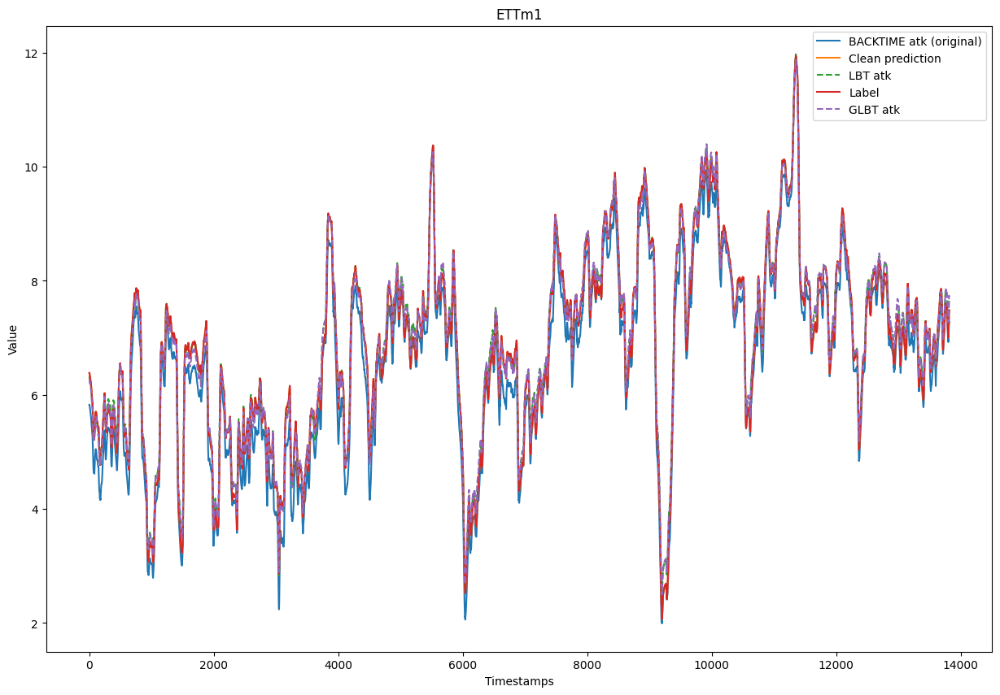

In [31]:
plt.figure(figsize=(15, 10))
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="ETTm1",
                           mode = 'atk')

In [4]:
def mini_visualize_backdoor_pattern(global_atk_prediction, 
                               global_atk_label,
                               global_clean_label, 
                               global_clean_prediction, 
                               local_atk_prediction, 
                               local_clean_prediction,
                               global_local_atk_prediction,
                               global_local_clean_prediction,
                               title,
                               feature_id,
                               mode='atk'):
    
    global_atk_prediction_mean  = global_atk_prediction[:,feature_id].tolist()
    global_atk_label_mean = global_atk_label[:,feature_id].tolist()
    
    global_clean_label_mean = global_clean_label[:,feature_id].tolist()
    global_clean_prediction_mean = global_clean_prediction[:,feature_id].tolist()

    local_atk_prediction_mean = local_atk_prediction[:,feature_id].tolist()
    local_clean_prediction_mean = local_clean_prediction[:,feature_id].tolist()
    
    global_local_atk_prediction_mean = global_local_atk_prediction[:,feature_id].tolist()
    global_local_clean_prediction_mean = global_local_clean_prediction[:,feature_id].tolist()
    

    import numpy as np
    import matplotlib.pyplot as plt

    def moving_avg(arr, window, stride=10):
        arr = np.asarray(arr)
        if window <= 1:
            return arr
        # simple convolution moving average
        kernel = np.ones(window) / window
        return np.convolve(arr, kernel, mode='valid')

    # def moving_avg(arr, window):
    #     # return np.round(arr, window)
    #     return arr

    window = 150  # smooth over 50 timesteps (tune)
    stride = 10   # plot every 10th smoothed point (tune)

    global_atk_prediction_smooth  = moving_avg(global_atk_prediction_mean, window)
    global_atk_label_smooth = moving_avg(global_atk_label_mean, window)
    global_clean_prediction_smooth = moving_avg(global_clean_prediction_mean, window)
    global_clean_label_smooth = moving_avg(global_clean_label_mean, window)
    local_atk_prediction_smooth = moving_avg(local_atk_prediction_mean, window)
    local_clean_prediction_smooth = moving_avg(local_clean_prediction_mean, window)
    global_local_atk_prediction_smooth = moving_avg(global_local_atk_prediction_mean, window)
    global_local_clean_prediction_smooth = moving_avg(global_local_clean_prediction_mean, window)


    # plt.figure(figsize=(15, 8))
    plt.title(title)
    import seaborn as sns
    palette = sns.color_palette('bright')
    if mode == 'atk':
        sns.lineplot(y=global_atk_prediction_smooth, x=np.arange(len(global_atk_prediction_smooth)), label='BACKTIME atk (original)', color=palette[0], linestyle='-')
        sns.lineplot(y=global_atk_label_smooth, x=np.arange(len(global_atk_label_smooth)), label='Clean prediction', color=palette[1])
        sns.lineplot(y=local_atk_prediction_smooth, x=np.arange(len(local_atk_prediction_smooth)), label='LBT atk', color=palette[2], linestyle='--')
        sns.lineplot(y=global_atk_label_smooth, x=np.arange(len(global_atk_label_smooth)), label='Label', color=palette[3])
        sns.lineplot(y=global_local_atk_prediction_smooth, x=np.arange(len(global_local_atk_prediction_smooth)), label='GLBT atk', color=palette[4], linestyle='--')
        plt.legend()
        plt.xlabel('Timestamps')
        plt.ylabel('Value')
        plt.show()
    elif mode == 'clean':
        sns.lineplot(y=global_clean_prediction_smooth, x=np.arange(len(global_clean_prediction_smooth)), label='BACKTIME clean (original)', color=palette[0], linestyle='-')
        sns.lineplot(y=local_clean_prediction_smooth, x=np.arange(len(local_clean_prediction_smooth)), label='LocalBACKTIME clean', color=palette[2], linestyle='--')
        sns.lineplot(y=global_clean_label_smooth, x=np.arange(len(global_clean_label_smooth)), label='Label', color=palette[3])
        sns.lineplot(y=global_local_clean_prediction_smooth, x=np.arange(len(global_local_clean_prediction_smooth)), label='GLBACKTIME clean', color=palette[4], linestyle='--')
        plt.legend()
        plt.show()


for feature_id in range(global_atk_prediction.shape[1]):
    plt.figure(figsize=(15, 10))
    mini_visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                            global_atk_label=global_atk_targets,
                            global_clean_label=global_clean_targets, 
                            global_clean_prediction=global_clean_prediction, 
                            local_atk_prediction=local_atk_prediction, 
                            local_clean_prediction=local_clean_prediction,
                            global_local_atk_prediction=global_local_atk_prediction,
                            global_local_clean_prediction=global_local_clean_prediction,
                            title=f"ETTm1 - variable {feature_id}",
                            feature_id=feature_id,
                            mode = 'atk')

NameError: name 'global_atk_prediction' is not defined

### TimesNet

In [36]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrGCN_TimesNet_TimesNet/ETTm1_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrCNN1D_TimesNet_TimesNet/ETTm1_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/ETTm1_cone_TgrHybridGCN_TimesNet_TimesNet/ETTm1_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

1.2879338264465332 1.0145349502563477
1.307748317718506 0.7807952165603638
1.3285064697265625 0.8569213151931763


# Weather

In [5]:
data_path = "/home/tanpham/BadFedBacktime/data/all_datasets/weather/weather.csv"
df = pd.read_csv(data_path)
df.head()


,date,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m�),PAR (�mol/m�/s),max. PAR (�mol/m�/s),Tlog (degC),OT
0,2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,...,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45,428.1
1,2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,...,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51,428.0
2,2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,...,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60,427.6
3,2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,...,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70,430.0
4,2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,...,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81,432.2


In [6]:
for item in df.columns:
    print(item, df[item].describe())
    print("-"*100)

date count                   52696
unique                  52695
top       2020-05-12 06:00:00
freq                        2
Name: date, dtype: object
----------------------------------------------------------------------------------------------------
p (mbar) count    52696.000000
mean       989.989233
std          9.207149
min        955.580000
25%        984.800000
50%        990.920000
75%        995.930000
max       1020.070000
Name: p (mbar), dtype: float64
----------------------------------------------------------------------------------------------------
T (degC) count    52696.000000
mean        10.818241
std          7.468671
min         -6.440000
25%          4.590000
50%         10.230000
75%         16.180000
max         34.800000
Name: T (degC), dtype: float64
----------------------------------------------------------------------------------------------------
Tpot (K) count    52696.000000
mean       284.796938
std          7.616995
min        266.190000
25%        278.55

In [7]:
feature_column = df.drop(columns=['date']).columns.tolist()
feature_column


['p (mbar)',
 'T (degC)',
 'Tpot (K)',
 'Tdew (degC)',
 'rh (%)',
 'VPmax (mbar)',
 'VPact (mbar)',
 'VPdef (mbar)',
 'sh (g/kg)',
 'H2OC (mmol/mol)',
 'rho (g/m**3)',
 'wv (m/s)',
 'max. wv (m/s)',
 'wd (deg)',
 'rain (mm)',
 'raining (s)',
 'SWDR (W/m�)',
 'PAR (�mol/m�/s)',
 'max. PAR (�mol/m�/s)',
 'Tlog (degC)',
 'OT']

In [8]:
weather_dataset = load_raw_data(edict(config['Dataset']['Weather']))
print("Dataset shape: ", weather_dataset[0].shape, weather_dataset[1].shape, weather_dataset[2].shape, weather_dataset[3].shape)
print("Dataset type: ", type(weather_dataset[0]), type(weather_dataset[1]), type(weather_dataset[2]), type(weather_dataset[3]))

Dataset shape:  () () (31617, 21, 1) (10540, 21, 1)
Dataset type:  <class 'numpy.float64'> <class 'numpy.float64'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>


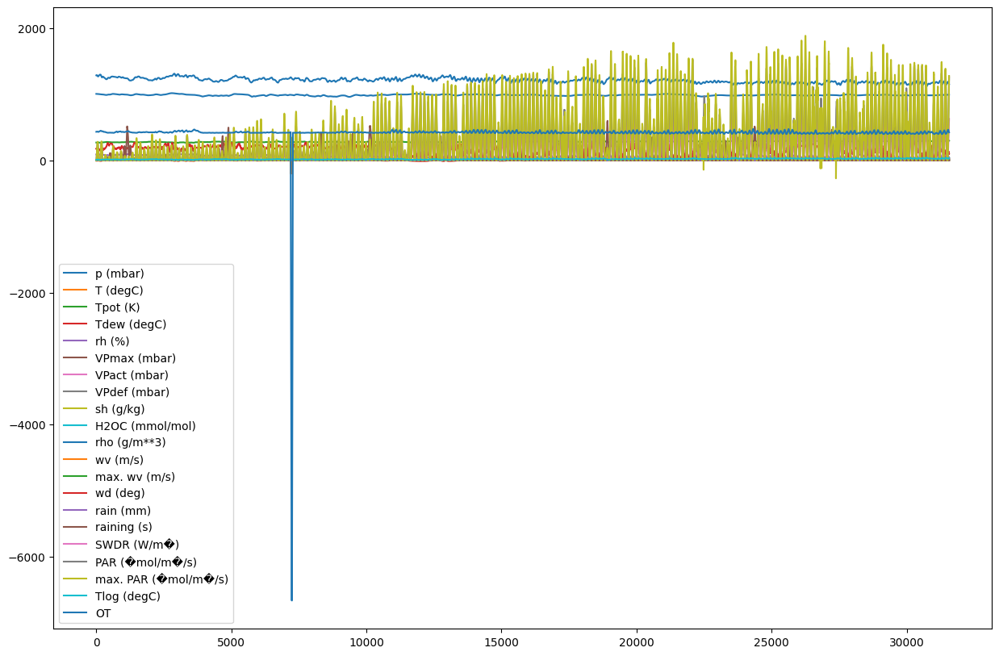

In [9]:
def moving_avg(arr, window):
    arr = np.asarray(arr)
    if window <= 1:
        return arr
    # simple convolution moving average
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode='valid')

plt.figure(figsize=(15, 10))
window = 50   # smooth over 50 timesteps (tune)
stride = 10   # plot every 10th smoothed point (tune)
test_mean = einops.rearrange(weather_dataset[2], "b c t -> b (c t)")

for i in range(test_mean.shape[1]):
    feature_type = feature_column[i]
    test_mean_smooth  = moving_avg(test_mean[:, i], window)
    plt.plot(test_mean_smooth, label=feature_type)
plt.legend()
plt.show()

## Autoformer

In [9]:
import pandas as pd
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])


9.078170776367188 7.886811256408691


In [10]:
local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_Autoformer_Autoformer/Weather_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

8.930533409118652 8.05742359161377


In [11]:
global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

9.067975044250488 8.744854927062988


#### Visualization analysis

In [9]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_140.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_140.npy")

global_atk_targets = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_140.npy")

global_clean_targets = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_targets_epoch99_victim_179.npy")

local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_Autoformer_Autoformer/Weather_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_180.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_Autoformer_Autoformer/Weather_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_180.npy")

global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_179.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_179.npy")

print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")
global_clean_targets = einops.rearrange(global_clean_targets, "b c t -> b (c t)")
global_atk_targets = einops.rearrange(global_atk_targets, "b c t -> b (c t)")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)


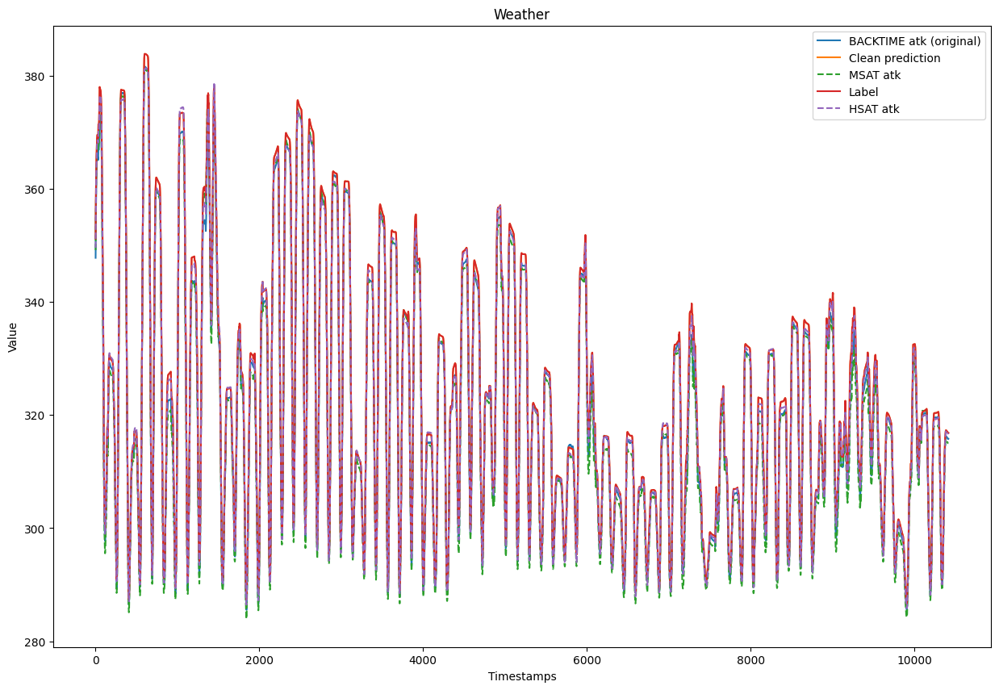

In [10]:
plt.figure(figsize=(15, 10))
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="Weather",
                           mode = 'atk')

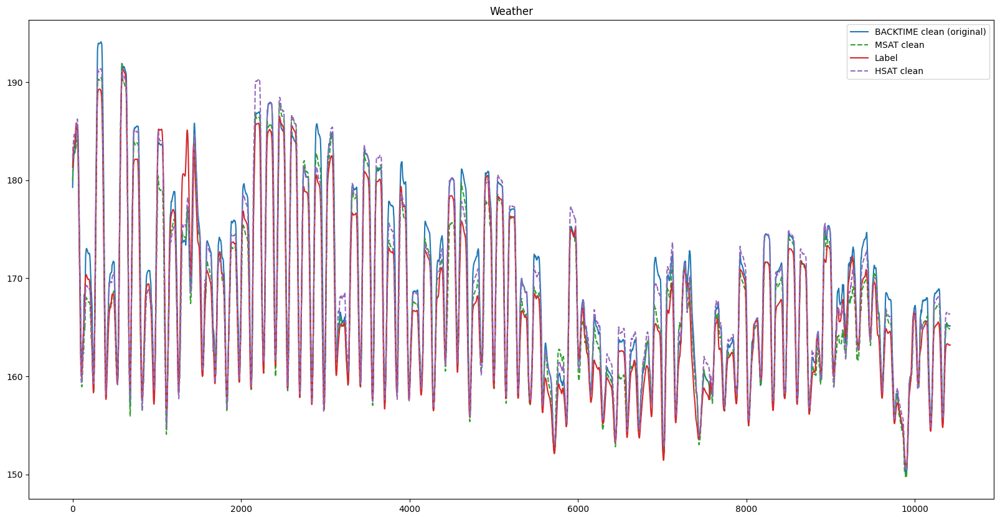

In [11]:
plt.figure(figsize=(20, 10))
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="Weather",
                           mode = 'clean')

In [12]:
global_atk_prediction.shape

(10517, 42)

In [15]:
def mini_visualize_backdoor_pattern(global_atk_prediction, 
                               global_atk_label,
                               global_clean_label, 
                               global_clean_prediction, 
                               local_atk_prediction, 
                               local_clean_prediction,
                               global_local_atk_prediction,
                               global_local_clean_prediction,
                               title,
                               feature_id,
                               mode='atk',
                               plot=True):
    
    from sklearn.metrics import mean_absolute_error
    print("Feature_id = ", feature_id)
    print("[BACKTIME] clean MAE = ", mean_absolute_error(global_clean_label[:, feature_id].tolist(), global_clean_prediction[:, feature_id].tolist()))
    print("[BACKTIME] atk MAE = ", mean_absolute_error(global_atk_label[:, feature_id].tolist(), global_atk_prediction[:, feature_id].tolist()))
    print("[MSAT] clean MAE = ", mean_absolute_error(global_clean_label[:, feature_id].tolist(), local_clean_prediction[:, feature_id].tolist()))
    print("[MSAT] atk MAE = ", mean_absolute_error(global_atk_label[:, feature_id].tolist(), local_atk_prediction[:, feature_id].tolist()))
    print("[HSAT] clean MAE = ", mean_absolute_error(global_clean_label[:, feature_id].tolist(), global_local_clean_prediction[:, feature_id].tolist()))
    print("[HSAT] atk MAE = ", mean_absolute_error(global_atk_label[:, feature_id].tolist(), global_local_atk_prediction[:, feature_id].tolist()))


    print("=="*40)

    global_atk_prediction_mean  = global_atk_prediction[:,feature_id].tolist()
    global_atk_label_mean = global_atk_label[:,feature_id].tolist()
    
    global_clean_label_mean = global_clean_label[:,feature_id].tolist()
    global_clean_prediction_mean = global_clean_prediction[:,feature_id].tolist()

    local_atk_prediction_mean = local_atk_prediction[:,feature_id].tolist()
    local_clean_prediction_mean = local_clean_prediction[:,feature_id].tolist()
    
    global_local_atk_prediction_mean = global_local_atk_prediction[:,feature_id].tolist()
    global_local_clean_prediction_mean = global_local_clean_prediction[:,feature_id].tolist()
    
    if plot:
        import numpy as np
        import matplotlib.pyplot as plt

        def moving_avg(arr, window, stride=10):
            arr = np.asarray(arr)
            if window <= 1:
                return arr
            # simple convolution moving average
            kernel = np.ones(window) / window
            return np.convolve(arr, kernel, mode='valid')

        # def moving_avg(arr, window):
        #     # return np.round(arr, window)
        #     return arr

        window = 100  # smooth over 50 timesteps (tune)
        stride = 10   # plot every 10th smoothed point (tune)

        global_atk_prediction_smooth  = moving_avg(global_atk_prediction_mean, window)
        global_atk_label_smooth = moving_avg(global_atk_label_mean, window)
        global_clean_prediction_smooth = moving_avg(global_clean_prediction_mean, window)
        global_clean_label_smooth = moving_avg(global_clean_label_mean, window)
        local_atk_prediction_smooth = moving_avg(local_atk_prediction_mean, window)
        local_clean_prediction_smooth = moving_avg(local_clean_prediction_mean, window)
        global_local_atk_prediction_smooth = moving_avg(global_local_atk_prediction_mean, window)
        global_local_clean_prediction_smooth = moving_avg(global_local_clean_prediction_mean, window)


        # plt.figure(figsize=(15, 8))
        import seaborn as sns

        # Use the seaborn colorblind palette for all plots in this function
        color_palette = sns.color_palette('bright')
        c0, c1, c2, c3, c4 = color_palette[:5]
        # Convenient color assignment
        # c0, c1, c2, c3, c4 = color_palette + [None]*(7-len(color_palette))

        # sns.set(style="whitegrid", palette="colorblind")
        plt.figure()
        plt.figure(figsize=(15, 8))
        plt.title(title)
        if mode == 'atk':
            # Assign colorblind palette colors
            plt.plot(global_atk_prediction_smooth, label='BACKTIME atk (original)', color=c0, linestyle='-')
            plt.plot(global_atk_label_smooth, label='Benign prediction', color=c1)
            plt.plot(local_atk_prediction_smooth, label='MSAT atk', color=c2, linestyle='--')
            plt.plot(global_atk_label_smooth, label='Label', color=color_palette[3])
            plt.plot(global_local_atk_prediction_smooth, label='HSAT atk', color=color_palette[4], linestyle='--')
            plt.legend()
            plt.xlabel('Timestamps')
            plt.ylabel('Value')
            
            plt.show()

for feature_id, feature_name in enumerate(feature_column):
    print(feature_name)
    mini_visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                            global_atk_label=global_atk_targets,
                            global_clean_label=global_clean_targets, 
                            global_clean_prediction=global_clean_prediction, 
                            local_atk_prediction=local_atk_prediction, 
                            local_clean_prediction=local_clean_prediction,
                            global_local_atk_prediction=global_local_atk_prediction,
                            global_local_clean_prediction=global_local_clean_prediction,
                            title="Weather - " + feature_name,
                            feature_id=feature_id,
                            mode = 'atk',
                            plot=False)

p (mbar)
Feature_id =  0
[BACKTIME] clean MAE =  0.5853830823384164
[BACKTIME] atk MAE =  6.859350482127825
[MSAT] clean MAE =  0.5439741905961776
[MSAT] atk MAE =  5.029435550145259
[HSAT] clean MAE =  0.4376325746039151
[HSAT] atk MAE =  7.869436854360402
T (degC)
Feature_id =  1
[BACKTIME] clean MAE =  0.5269811714576886
[BACKTIME] atk MAE =  4.72386319888707
[MSAT] clean MAE =  0.4959901086725716
[MSAT] atk MAE =  3.1927278175364884
[HSAT] clean MAE =  0.3749612198404566
[HSAT] atk MAE =  4.980508770769944
Tpot (K)
Feature_id =  2
[BACKTIME] clean MAE =  0.4515049800091147
[BACKTIME] atk MAE =  4.493860089689354
[MSAT] clean MAE =  0.4544058561529102
[MSAT] atk MAE =  3.203130766841478
[HSAT] clean MAE =  0.5389522339575211
[HSAT] atk MAE =  5.884214082598017
Tdew (degC)
Feature_id =  3
[BACKTIME] clean MAE =  1.4447501054246343
[BACKTIME] atk MAE =  10.04555896897954
[MSAT] clean MAE =  1.9078484429784166
[MSAT] atk MAE =  21.26979709707581
[HSAT] clean MAE =  1.3666299134230755
[

## TimesNet

In [49]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

10.415441513061523 5.260990142822266


In [50]:
local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_TimesNet_TimesNet/Weather_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

17.533004760742188 5.536962032318115


In [51]:
global_local_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print(global_local_mae[global_local_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_mae[global_local_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

14.316658973693848 4.839912414550781


In [52]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")
global_atk_targets = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_199.npy")
global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")
global_clean_targets = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_targets_epoch99_victim_199.npy")

# add local and global local also
local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_TimesNet_TimesNet/Weather_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_180.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_TimesNet_TimesNet/Weather_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_180.npy")

global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_180.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_TimesNet_TimesNet/Weather_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.04_epsilon=0.3_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_180.npy")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")
global_clean_targets = einops.rearrange(global_clean_targets, "b c t -> b (c t)")
global_atk_targets = einops.rearrange(global_atk_targets, "b c t -> b (c t)")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 7, 6) (10517, 12, 21)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)
(10517, 42) (10517, 252)


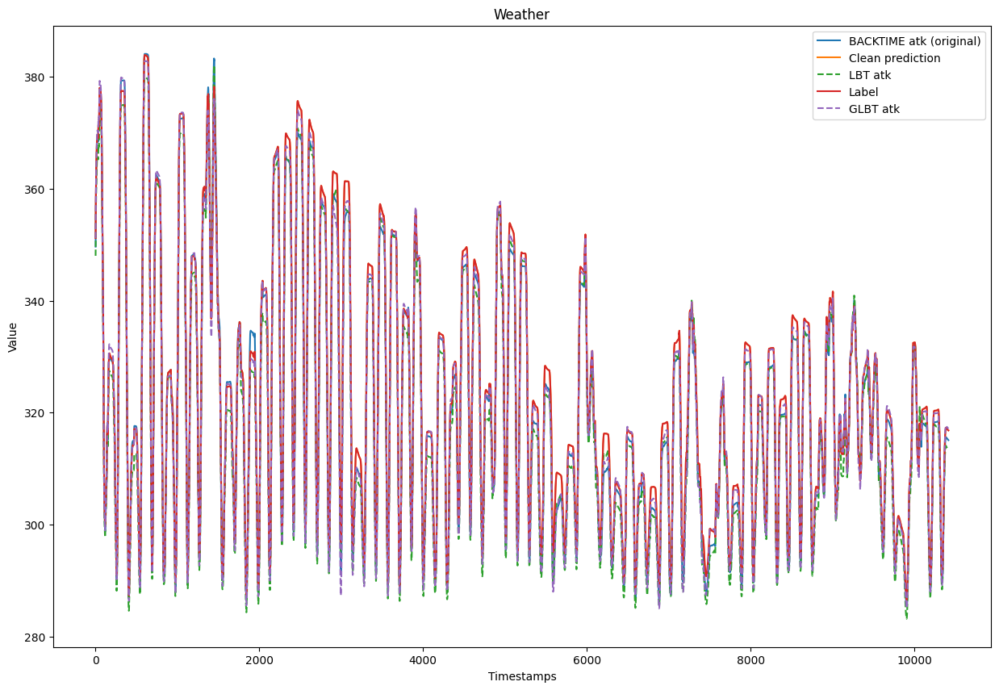

In [53]:
plt.figure(figsize=(15, 10))
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="Weather",
                           mode = 'atk')

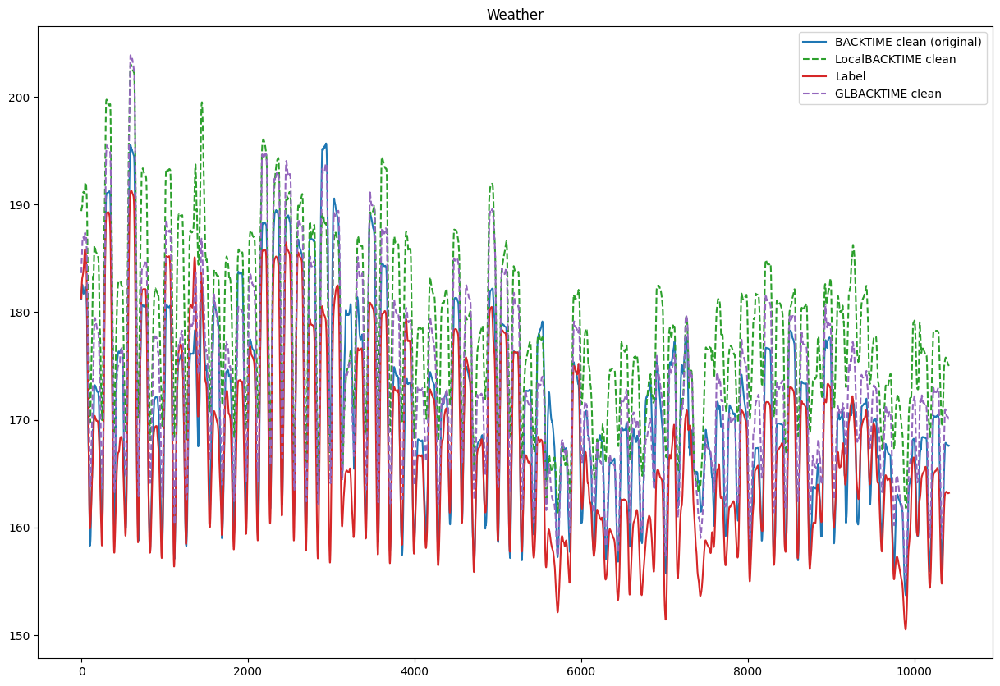

In [54]:
plt.figure(figsize=(15, 10))
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_atk_label=global_atk_targets,
                           global_clean_label=global_clean_targets, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="Weather",
                           mode = 'clean')

## Fedformer

In [55]:
global_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_FEDformer_FEDformer/Weather_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
print(global_atk_mae[global_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_atk_mae[global_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

9.721851348876951 7.669465065002441


In [56]:
local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_FEDformer_FEDformer/Weather_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")
print(local_atk_mae[local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], local_atk_mae[local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

9.21285343170166 8.932085037231445


In [57]:
global_local_atk_mae = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_FEDformer_FEDformer/Weather_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")
print(global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['clean_mae'].tolist()[-1], global_local_atk_mae[global_local_atk_mae['phase'] == 'victim']['attacked_mae'].tolist()[-1])

8.658669471740723 5.631963729858398


# PEMS03

In [64]:
dataset_name = "PEMS03"
data_config = edict(config['Dataset'][dataset_name])

if not data_config.use_timestamps:
    train_mean, train_std, train_data_seq, test_data_seq = load_raw_data(data_config)
    train_data_stamps = test_data_stamps = None

In [65]:
print(train_data_seq.shape, test_data_seq.shape)
train_data_seq.mean(axis=1).squeeze(1).shape, test_data_seq.mean(axis=1).squeeze(1).shape

(15724, 358, 1) (5242, 358, 1)


((15724,), (5242,))

In [66]:
atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_99.npy")
atk_prediction = einops.rearrange(atk_prediction, "b c t -> b (c t)")
atk_prediction.shape

(5219, 749)

In [67]:
atk_target = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_targets_epoch99_victim_99.npy")
atk_target = einops.rearrange(atk_target, "b c t -> b (c t)")
atk_target.shape


(5219, 749)

In [68]:
clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_99.npy")
clean_prediction = einops.rearrange(clean_prediction, "b c t -> b (c t)")
clean_prediction.shape

(5219, 4296)

In [69]:
clean_target = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_targets_epoch99_victim_99.npy")
clean_target = einops.rearrange(clean_target, "b c t -> b (c t)")
clean_target.shape


(5219, 4296)

5219 5219


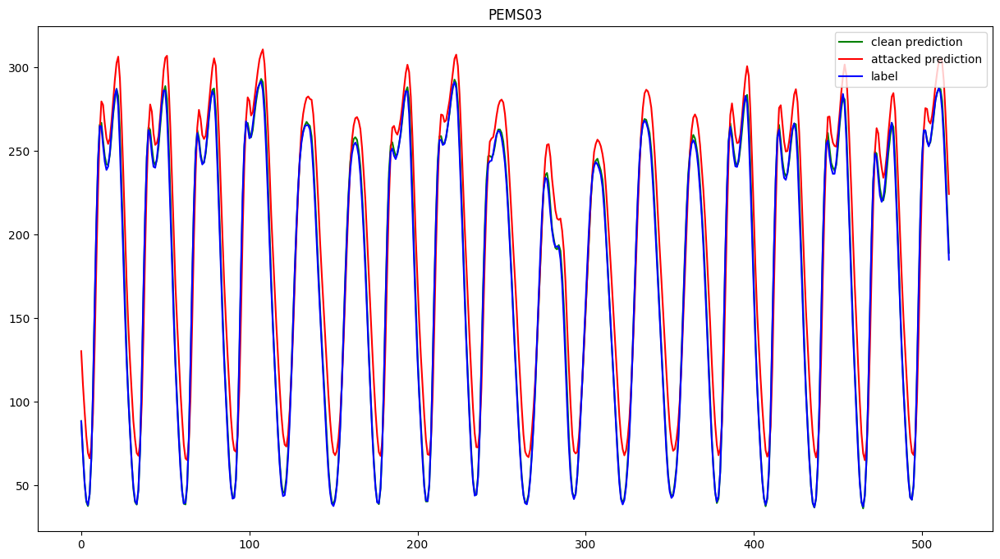

In [70]:
# train_mean = train_data_seq.mean(axis=1).squeeze(1).tolist()
test_mean  = clean_target.mean(axis=1).tolist()
clean_prediction_mean = clean_prediction.mean(axis=1).tolist()
atk_target_mean = atk_target.mean(axis=1).tolist()
atk_prediction_mean = atk_prediction.mean(axis=1).tolist()  
# clean_prediction = clean_prediction.squeeze(1).tolist()
print(len(clean_prediction_mean), len(test_mean))

def moving_avg(arr, window):
    arr = np.asarray(arr)
    if window <= 1:
        return arr
    # simple convolution moving average
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode='valid')

window = 50   # smooth over 50 timesteps (tune)
stride = 10   # plot every 10th smoothed point (tune)

test_mean_smooth  = moving_avg(test_mean, window)
clean_prediction_smooth = moving_avg(clean_prediction_mean, window)
atk_prediction_smooth = moving_avg(atk_prediction_mean, window)
atk_target_smooth = moving_avg(atk_target_mean, window)

# x_train_s = np.arange(1, len(y_train_smooth)+1)[::stride]
x_test_s  = np.arange(1, len(clean_prediction_mean)+1)[::stride]

plt.figure(figsize=(15, 8))
plt.title("PEMS03")
# plt.plot(x_train_s, y_train_smooth[::stride], label='train', linewidth=1.8)
# print(len(x_test_s))
plt.plot(clean_prediction_smooth[::stride],  label='clean prediction', c='green')
plt.plot(atk_prediction_smooth[::stride],  label='attacked prediction', c='red')
# plt.plot(atk_target_smooth[::stride],  label='attacked target', c='black')
plt.plot(test_mean_smooth[::stride],  label='label', c='blue')
plt.title("PEMS03")
plt.legend()
plt.show()


In [71]:
import numpy as np
df = np.load("/home/tanpham/BadFedBacktime/data/PEMS04/PEMS04.npz")['data']
# df

(3376, 7, 92) (10517, 12, 21)
(3376, 7, 92) (10517, 12, 21)
(3376, 7, 92) (10517, 12, 21)
(3376, 7, 92) (10517, 12, 21)
(3376, 644) (10517, 12, 21)
(3376, 644) (10517, 12, 21)
(3376, 644) (10517, 12, 21)
(3376, 644) (10517, 12, 21)


<Figure size 640x480 with 0 Axes>

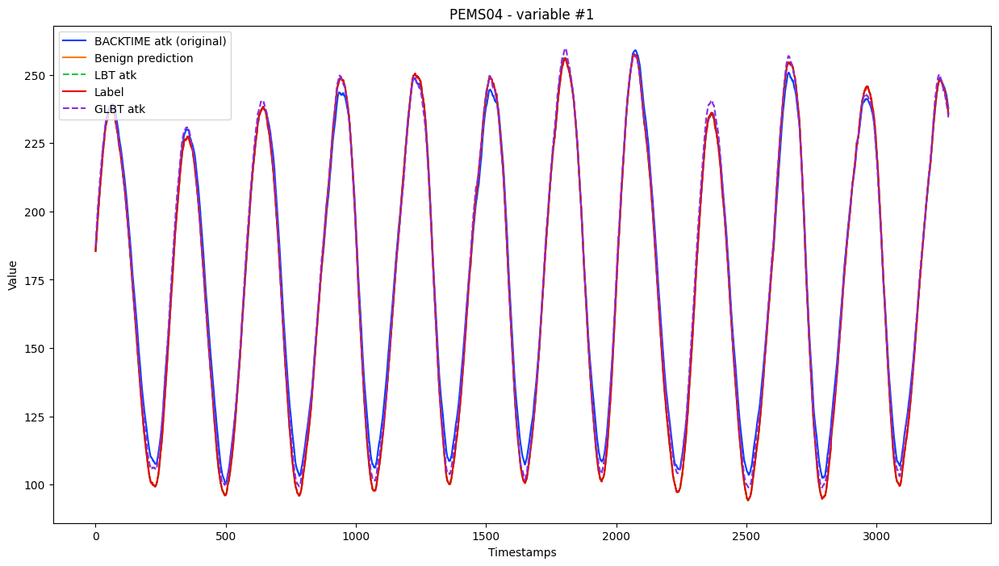

<Figure size 640x480 with 0 Axes>

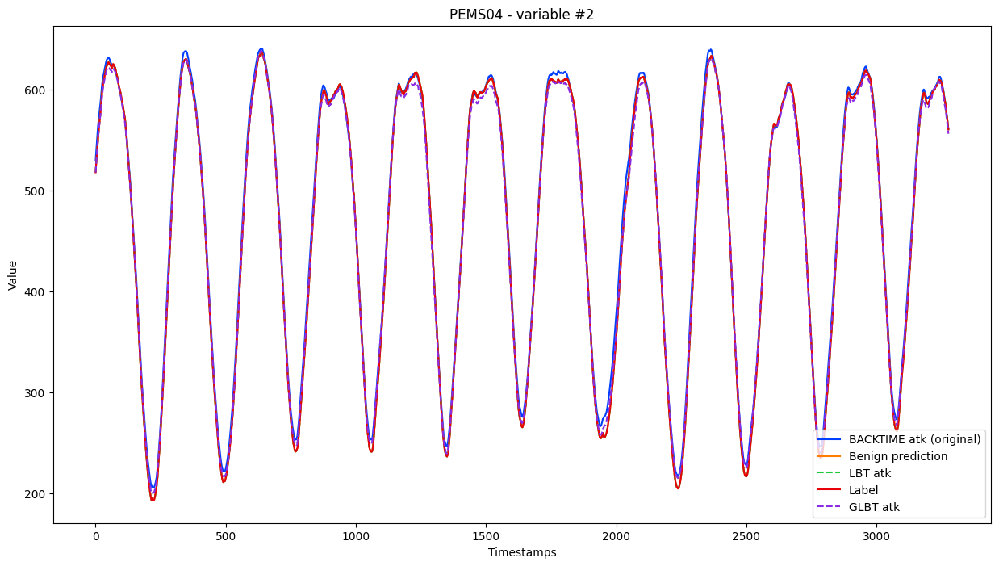

<Figure size 640x480 with 0 Axes>

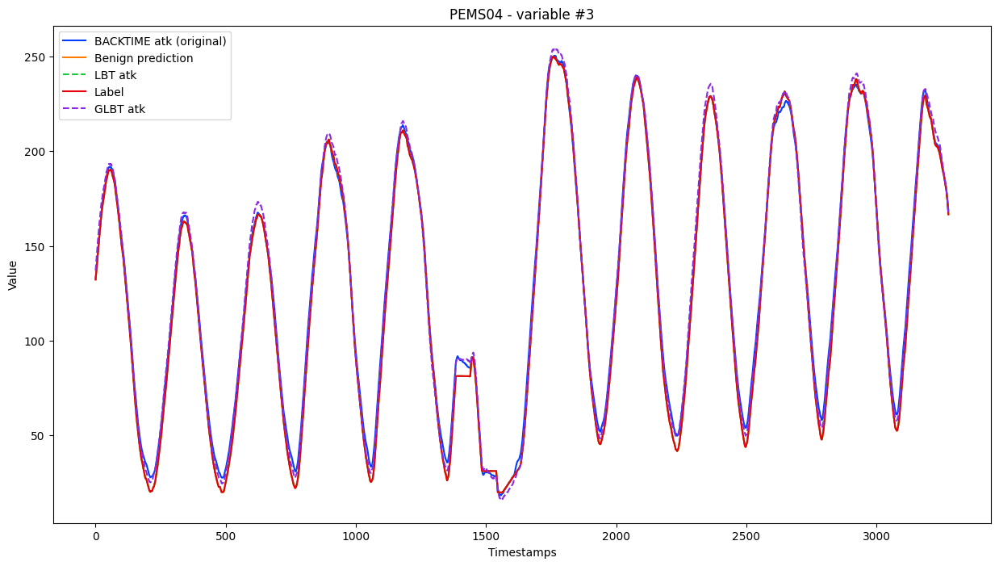

<Figure size 640x480 with 0 Axes>

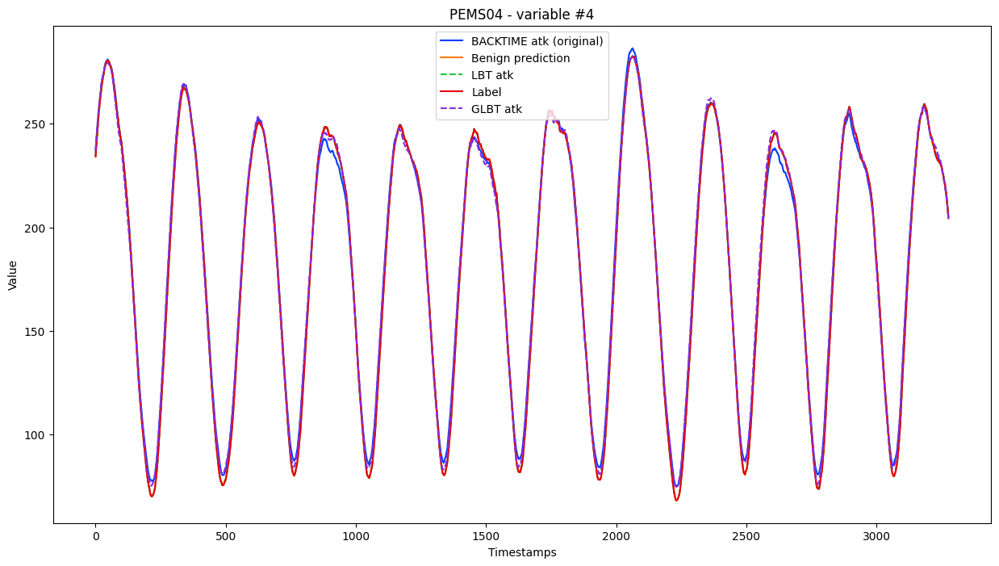

<Figure size 640x480 with 0 Axes>

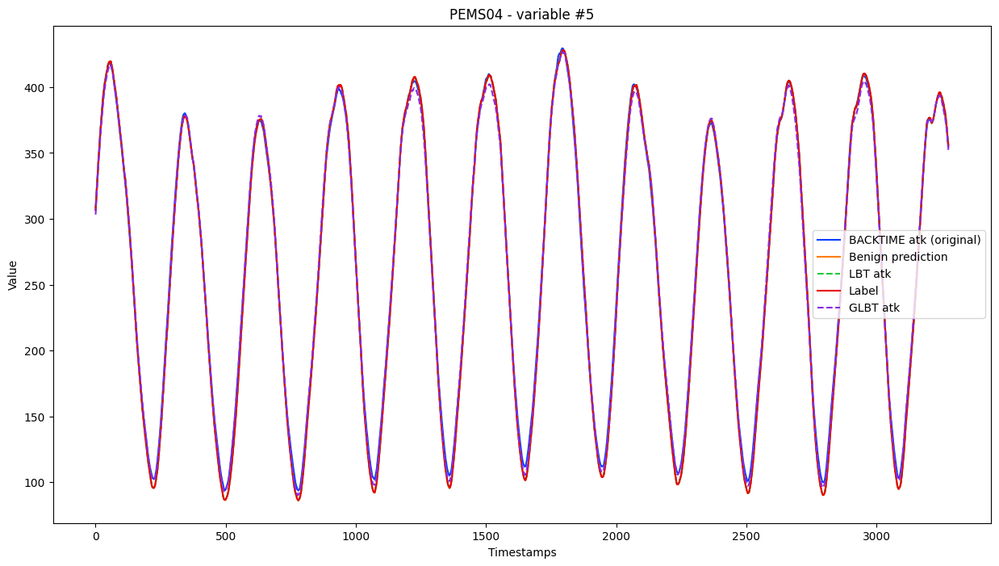

<Figure size 640x480 with 0 Axes>

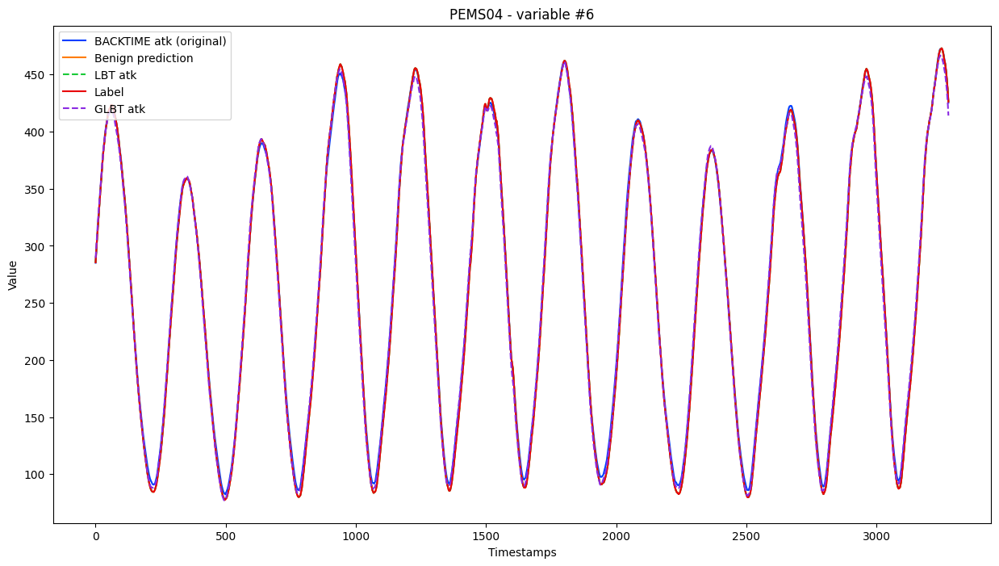

<Figure size 640x480 with 0 Axes>

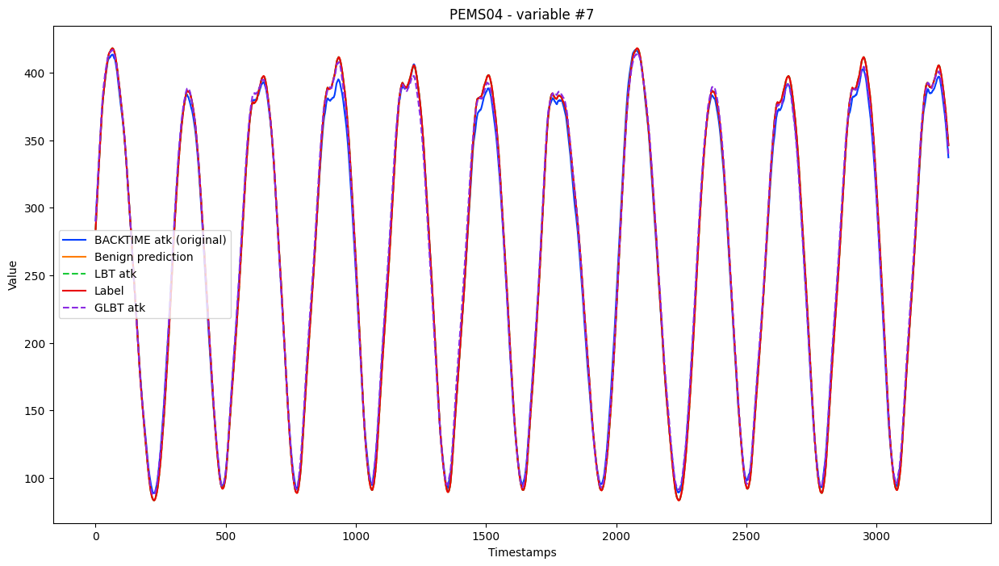

<Figure size 640x480 with 0 Axes>

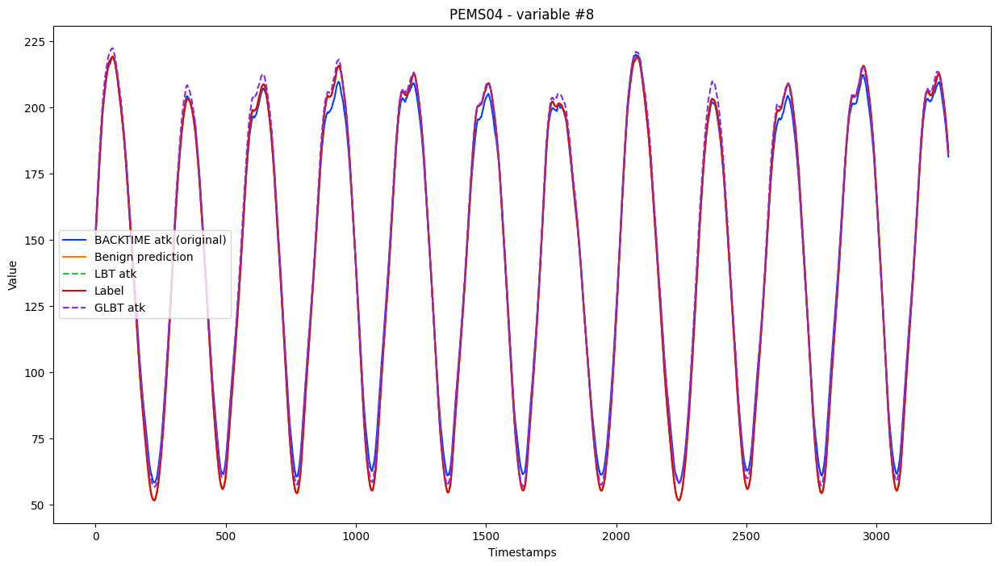

<Figure size 640x480 with 0 Axes>

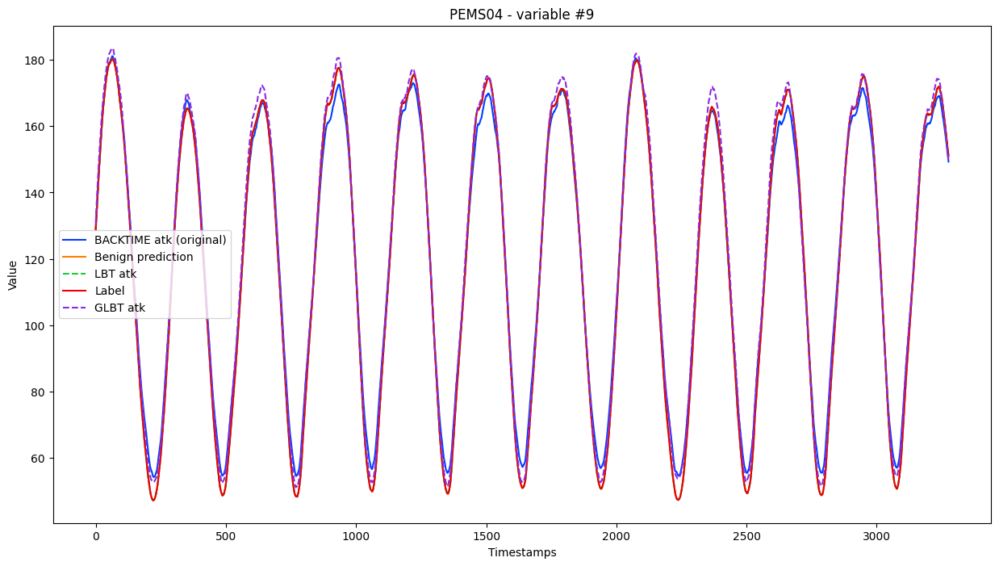

<Figure size 640x480 with 0 Axes>

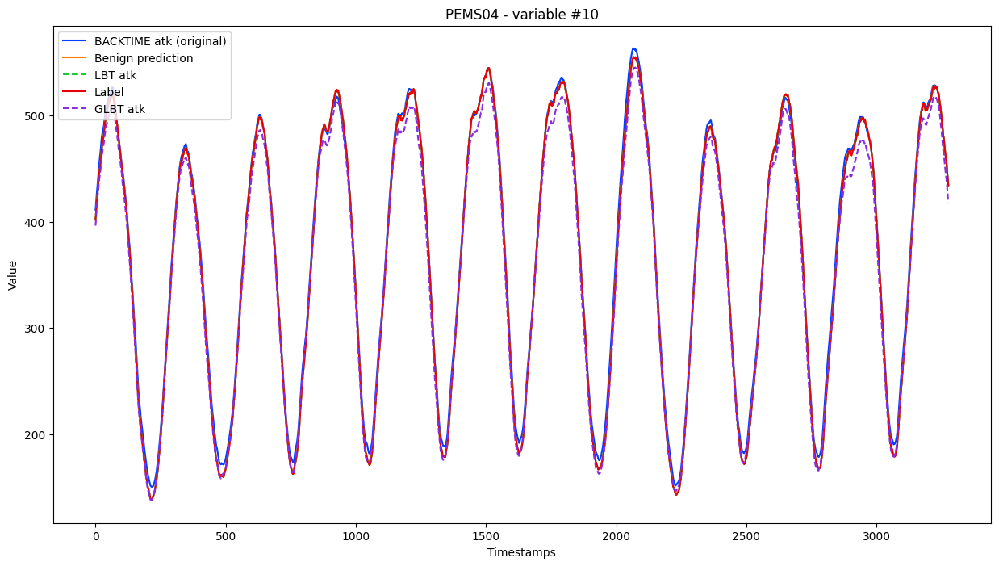

<Figure size 640x480 with 0 Axes>

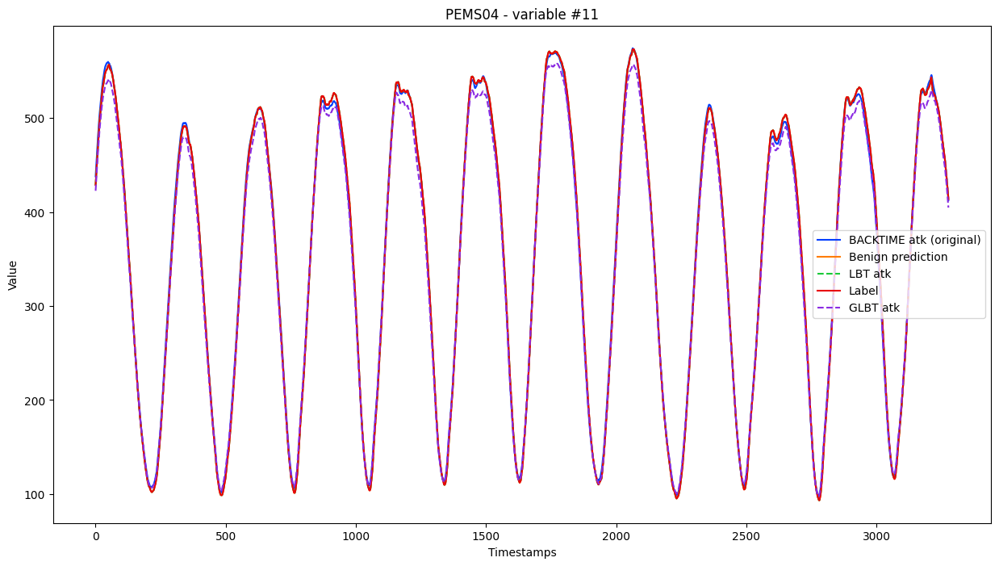

<Figure size 640x480 with 0 Axes>

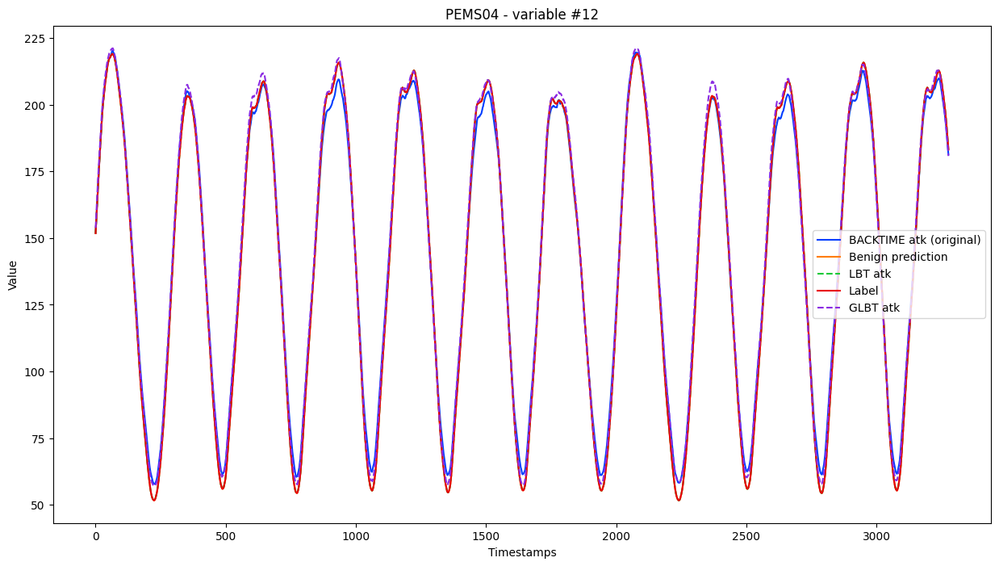

IndexError: index 12 is out of bounds for axis 1 with size 12

In [72]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_Autoformer_Autoformer/PEMS04_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_140.npy")

global_atk_targets = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_Autoformer_Autoformer/PEMS04_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_180.npy")

global_clean_targets = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_targets_epoch99_victim_179.npy")

local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_Autoformer_Autoformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_180.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrCNN1D_Autoformer_Autoformer/Weather_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_180.npy")

global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_180.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/Weather_cone_TgrHybridGCN_Autoformer_Autoformer/Weather_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_179.npy")

print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
# global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
# local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
# global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")
# global_clean_targets = einops.rearrange(global_clean_targets, "b c t -> b (c t)")
global_atk_targets = einops.rearrange(global_atk_targets, "b c t -> b (c t)")


print(global_atk_prediction.shape, global_clean_prediction.shape)
print(local_atk_prediction.shape, local_clean_prediction.shape)
print(global_local_atk_prediction.shape, global_local_clean_prediction.shape)
print(global_atk_targets.shape, global_clean_targets.shape)

def mini_visualize_backdoor_pattern(global_atk_prediction, 
                               global_atk_label,
                               global_clean_label, 
                               global_clean_prediction, 
                               local_atk_prediction, 
                               local_clean_prediction,
                               global_local_atk_prediction,
                               global_local_clean_prediction,
                               title,
                               feature_id,
                               mode='atk'):
    
    global_atk_prediction_mean  = global_atk_prediction[:,feature_id].tolist()
    global_atk_label_mean = global_atk_label[:,feature_id].tolist()
    
    global_clean_label_mean = global_clean_label[:,feature_id].tolist()
    global_clean_prediction_mean = global_clean_prediction[:,feature_id].tolist()

    local_atk_prediction_mean = local_atk_prediction[:,feature_id].tolist()
    local_clean_prediction_mean = local_clean_prediction[:,feature_id].tolist()
    
    global_local_atk_prediction_mean = global_local_atk_prediction[:,feature_id].tolist()
    global_local_clean_prediction_mean = global_local_clean_prediction[:,feature_id].tolist()
    

    import numpy as np
    import matplotlib.pyplot as plt

    def moving_avg(arr, window, stride=10):
        arr = np.asarray(arr)
        if window <= 1:
            return arr
        # simple convolution moving average
        kernel = np.ones(window) / window
        return np.convolve(arr, kernel, mode='valid')

    # def moving_avg(arr, window):
    #     # return np.round(arr, window)
    #     return arr

    window = 100  # smooth over 50 timesteps (tune)
    stride = 10   # plot every 10th smoothed point (tune)

    global_atk_prediction_smooth  = moving_avg(global_atk_prediction_mean, window)
    global_atk_label_smooth = moving_avg(global_atk_label_mean, window)
    # global_clean_prediction_smooth = moving_avg(global_clean_prediction_mean, window)
    # global_clean_label_smooth = moving_avg(global_clean_label_mean, window)
    local_atk_prediction_smooth = moving_avg(local_atk_prediction_mean, window)
    # local_clean_prediction_smooth = moving_avg(local_clean_prediction_mean, window)
    global_local_atk_prediction_smooth = moving_avg(global_local_atk_prediction_mean, window)
    # global_local_clean_prediction_smooth = moving_avg(global_local_clean_prediction_mean, window)


    # plt.figure(figsize=(15, 8))
    import seaborn as sns

    # Use the seaborn colorblind palette for all plots in this function
    color_palette = sns.color_palette("bright")
    c0, c1, c2, c3, c4 = color_palette[:5]
    # Convenient color assignment
    # c0, c1, c2, c3, c4 = color_palette + [None]*(7-len(color_palette))

    # sns.set(style="whitegrid", palette="colorblind")
    plt.figure()
    plt.figure(figsize=(15, 8))
    plt.title(title)
    if mode == 'atk':
        # Assign colorblind palette colors
        plt.plot(global_atk_prediction_smooth, label='BACKTIME atk (original)', color=c0, linestyle='-')
        plt.plot(global_atk_label_smooth, label='Benign prediction', color=c1)
        plt.plot(local_atk_prediction_smooth, label='LBT atk', color=c2, linestyle='--')
        plt.plot(global_atk_label_smooth, label='Label', color=color_palette[3])
        plt.plot(global_local_atk_prediction_smooth, label='GLBT atk', color=color_palette[4], linestyle='--')
        plt.legend()
        plt.xlabel('Timestamps')
        plt.ylabel('Value')
        
        plt.show()
    # elif mode == 'clean':
    #     plt.plot(global_clean_prediction_smooth, label='BACKTIME clean (original)', color=c0, linestyle='-')
    #     plt.plot(local_clean_prediction_smooth, label='LocalBACKTIME clean', color=c2, linestyle='--')
    #     plt.plot(global_clean_label_smooth, label='Label', color=c3)
    #     plt.plot(global_local_clean_prediction_smooth, label='GLBACKTIME clean', color=c4, linestyle='--')
    #     plt.legend()
    #     plt.show()


# for feature_id, feature_name in enumerate(feature_column):
for feature_id in range(global_atk_prediction.shape[0]):
    mini_visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                            global_atk_label=global_atk_targets,
                            global_clean_label=global_clean_targets, 
                            global_clean_prediction=global_clean_prediction, 
                            local_atk_prediction=local_atk_prediction, 
                            local_clean_prediction=local_clean_prediction,
                            global_local_atk_prediction=global_local_atk_prediction,
                            global_local_clean_prediction=global_local_clean_prediction,
                            title="PEMS04 - variable #" + str(feature_id + 1),
                            feature_id=feature_id,
                            mode = 'atk')

# PEMS04

In [ ]:
dataset_name = "PEMS04"
data_config = edict(config['Dataset'][dataset_name])

if not data_config.use_timestamps:
    train_mean, train_std, train_data_seq, test_data_seq = load_raw_data(data_config)
    train_data_stamps = test_data_stamps = None

In [ ]:
import einops
print(train_data_seq.shape, test_data_seq.shape)
transformed_train_data_seq = einops.rearrange(train_data_seq, "b c t -> b (c t)")
transformed_test_data_seq = einops.rearrange(test_data_seq, "b c t -> b (c t)")
transformed_train_data_seq.mean(axis=1).shape, transformed_test_data_seq.mean(axis=1).shape

(10195, 307, 3) (3399, 307, 3)


((10195,), (3399,))

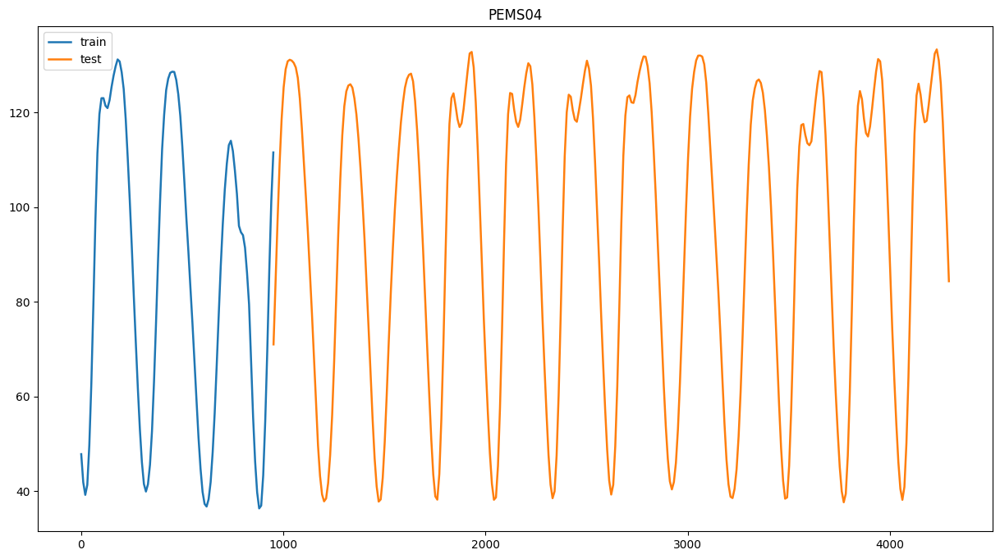

In [ ]:
train_mean = transformed_train_data_seq.mean(axis=1).tolist()
test_mean  = transformed_test_data_seq.mean(axis=1).tolist()

y_train = train_mean[-1000:]
y_test  = test_mean

import numpy as np
import matplotlib.pyplot as plt

def moving_avg(arr, window):
    arr = np.asarray(arr)
    if window <= 1:
        return arr
    # simple convolution moving average
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode='valid')

window = 50   # smooth over 50 timesteps (tune)
stride = 10   # plot every 10th smoothed point (tune)

y_train_smooth = moving_avg(y_train, window)
y_test_smooth  = moving_avg(y_test, window)

x_train_s = np.arange(1, len(y_train_smooth)+1)[::stride]
x_test_s  = np.arange(len(y_train_smooth)+1, len(y_train_smooth)+1 + len(y_test_smooth))[::stride]

plt.figure(figsize=(15, 8))
plt.title("PEMS04")
plt.plot(x_train_s, y_train_smooth[::stride], label='train', linewidth=1.8)
plt.plot(x_test_s,  y_test_smooth[::stride],  label='test', linewidth=1.8)
plt.legend()
plt.show()


## Autoformer

In [ ]:
df_global_autoformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_Autoformer_Autoformer/PEMS04_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
df_local_autoformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_Autoformer_Autoformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
df_global_local_autoformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print("Global Clean MAE", df_global_autoformer_pems04[df_global_autoformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_autoformer_pems04[df_global_autoformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_autoformer_pems04[df_local_autoformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_autoformer_pems04[df_local_autoformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_autoformer_pems04[df_global_local_autoformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_autoformer_pems04[df_global_local_autoformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 22.66929054260254
Global ATK MAE 22.638219833374023
Local Clean MAE 22.670528411865234
Local ATK MAE 22.49704933166504
Global Local Clean MAE 22.83869361877441
Global Local ATK MAE 23.040491104125977


In [ ]:
############ Global #####################
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")

global_clean_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS03_cone_TgrGCN_Autoformer_Autoformer/PEMS03_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_targets_epoch99_victim_199.npy")

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
# global_atk_label = einops.rearrange(global_atk_label, "b c t -> b (c t)")
global_clean_label = einops.rearrange(global_clean_label, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")

print("PEMS08: global atk, label, clean prediction", global_atk_prediction.shape, global_clean_prediction.shape)

############ Local #####################
local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_FEDformer_FEDformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_FEDformer_FEDformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")

print("Local atk pred, local clean pred: ",local_atk_prediction.shape, local_clean_prediction.shape)

############ global local #####################
global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_199.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_199.npy")

global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")

print("Global local atk pred, global local clean pred: ", global_local_atk_prediction.shape, global_local_clean_prediction.shape)

## Timesnet

In [ ]:
df_global_timesnet_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_TimesNet_TimesNet/PEMS04_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

df_local_timesnet_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_TimesNet_TimesNet/PEMS04_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

df_global_local_timesnet_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_TimesNet_TimesNet/PEMS04_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print("Global Clean MAE", df_global_timesnet_pems04[df_global_timesnet_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_timesnet_pems04[df_global_timesnet_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_timesnet_pems04[df_local_timesnet_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_timesnet_pems04[df_local_timesnet_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_timesnet_pems04[df_global_local_timesnet_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_timesnet_pems04[df_global_local_timesnet_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 24.895605087280277
Global ATK MAE 30.779598236083984
Local Clean MAE 25.266603469848636
Local ATK MAE 32.72574234008789
Global Local Clean MAE 24.70220184326172
Global Local ATK MAE 30.636449813842773


## Fedformer

#### Results

In [ ]:
df_global_fedformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
df_local_fedformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_FEDformer_FEDformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")
df_global_local_fedformer_pems04 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")
print("Global Clean MAE", df_global_fedformer_pems04[df_global_fedformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_fedformer_pems04[df_global_fedformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_fedformer_pems04[df_local_fedformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_fedformer_pems04[df_local_fedformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_fedformer_pems04[df_global_local_fedformer_pems04['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_fedformer_pems04[df_global_local_fedformer_pems04['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 21.93169403076172
Global ATK MAE 17.28476333618164
Local Clean MAE 21.758033752441406
Local ATK MAE 16.83771514892578
Global Local Clean MAE 22.07552146911621
Global Local ATK MAE 19.4167594909668


#### Visualization analysis

In [ ]:
############ Global #####################
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")

global_clean_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/clean_targets_epoch99_victim_199.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
# global_atk_label = einops.rearrange(global_atk_label, "b c t -> b (c t)")
global_clean_label = einops.rearrange(global_clean_label, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")

print("PEMS08: global atk, label, clean prediction", global_atk_prediction.shape, global_atk_label.shape, global_clean_prediction.shape)

############ Local #####################
local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_FEDformer_FEDformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")
local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrCNN1D_FEDformer_FEDformer/PEMS04_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_199.npy")

local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_clean_prediction = einops.rearrange(local_clean_prediction, "b c t -> b (c t)")

print("Local atk pred, local clean pred: ",local_atk_prediction.shape, local_clean_prediction.shape)

############ global local #####################
global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_199.npy")
global_local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS04_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS04_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_arrays/clean_predictions_epoch99_victim_199.npy")

global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_clean_prediction = einops.rearrange(global_local_clean_prediction, "b c t -> b (c t)")

print("Global local atk pred, global local clean pred: ", global_local_atk_prediction.shape, global_local_clean_prediction.shape)

PEMS08: global atk, label, clean prediction (3376, 644) (3376, 644) (3376, 3684)
Local atk pred, local clean pred:  (3376, 644) (3376, 3684)
Global local atk pred, global local clean pred:  (3376, 644) (3376, 3684)


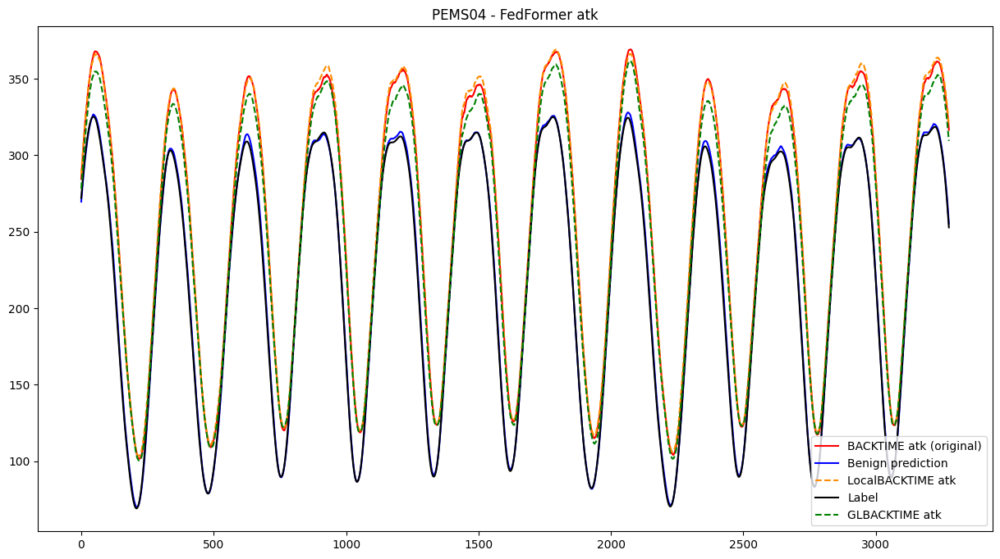

In [ ]:
def visualize_backdoor_pattern(global_atk_prediction, 
                            #    global_atk_label, 
                               global_clean_label, 
                               global_clean_prediction, 
                               local_atk_prediction, 
                               local_clean_prediction,
                               global_local_atk_prediction,
                               global_local_clean_prediction,
                               title,
                               mode='atk'):
    
    global_atk_prediction_mean  = global_atk_prediction.mean(axis=1).tolist()
    global_clean_label_mean = global_clean_label.mean(axis=1).tolist()
    global_clean_prediction_mean = global_clean_prediction.mean(axis=1).tolist()

    local_atk_prediction_mean = local_atk_prediction.mean(axis=1).tolist()
    local_clean_prediction_mean = local_clean_prediction.mean(axis=1).tolist()
    
    global_local_atk_prediction_mean = global_local_atk_prediction.mean(axis=1).tolist()
    global_local_clean_prediction_mean = global_local_clean_prediction.mean(axis=1).tolist()
    
    
    global_atk_prediction_std = global_atk_prediction.std(axis=1).tolist()
    global_clean_prediction_std = global_clean_prediction.std(axis=1).tolist()
    global_clean_label_std = global_clean_label.std(axis=1).tolist()
    local_atk_prediction_std = local_atk_prediction.std(axis=1).tolist()
    local_clean_prediction_std = local_clean_prediction.std(axis=1).tolist()
    global_local_atk_prediction_std = global_local_atk_prediction.std(axis=1).tolist()
    global_local_clean_prediction_std = global_local_clean_prediction.std(axis=1).tolist()

    import numpy as np
    import matplotlib.pyplot as plt

    def moving_avg(arr, window):
        arr = np.asarray(arr)
        if window <= 1:
            return arr
        # simple convolution moving average
        kernel = np.ones(window) / window
        return np.convolve(arr, kernel, mode='valid')

    window = 100  # smooth over 50 timesteps (tune)
    stride = 10   # plot every 10th smoothed point (tune)

    global_atk_prediction_smooth  = moving_avg(global_atk_prediction_mean, window)
    global_atk_prediction_std_smooth = moving_avg(global_atk_prediction_std, window)
    global_clean_prediction_smooth = moving_avg(global_clean_prediction_mean, window)
    global_clean_prediction_std_smooth = moving_avg(global_clean_prediction_std, window)
    global_clean_label_smooth = moving_avg(global_clean_label_mean, window)
    global_clean_label_std_smooth = moving_avg(global_clean_label_std, window)
    local_atk_prediction_smooth = moving_avg(local_atk_prediction_mean, window)
    local_atk_prediction_std_smooth = moving_avg(local_atk_prediction_std, window)
    local_clean_prediction_smooth = moving_avg(local_clean_prediction_mean, window)
    local_clean_prediction_std_smooth = moving_avg(local_clean_prediction_std, window)
    global_local_atk_prediction_smooth = moving_avg(global_local_atk_prediction_mean, window)
    global_local_atk_prediction_std_smooth = moving_avg(global_local_atk_prediction_std, window)
    global_local_clean_prediction_smooth = moving_avg(global_local_clean_prediction_mean, window)
    global_local_clean_prediction_std_smooth = moving_avg(global_local_clean_prediction_std, window)


    plt.figure(figsize=(15, 8))
    plt.title(title)
    if mode == 'atk':
        plt.plot(global_atk_prediction_smooth,  label=f'BACKTIME atk (original)', c='red', linestyle='-')
        # plt.fill_between(np.arange(1, len(global_atk_prediction_smooth)+1), global_atk_prediction_smooth - global_atk_prediction_std_smooth, global_atk_prediction_smooth + global_atk_prediction_std_smooth, alpha=0.2, color='red')
        plt.plot(global_clean_prediction_smooth,  label='Benign prediction', c='blue')
        # plt.fill_between(np.arange(1, len(global_clean_prediction_smooth)+1), global_clean_prediction_smooth - global_clean_prediction_std_smooth, global_clean_prediction_smooth + global_clean_prediction_std_smooth, alpha=0.2, color='green')
        plt.plot(local_atk_prediction_smooth,  label='LocalBACKTIME atk', c='darkorange', linestyle='--')
        # plt.fill_between(np.arange(1, len(local_atk_prediction_smooth)+1), local_atk_prediction_smooth - local_atk_prediction_std_smooth, local_atk_prediction_smooth + local_atk_prediction_std_smooth, alpha=0.2, color='darkorange')
        plt.plot(global_clean_label_smooth,  label='Label', c='black')
        # plt.fill_between(np.arange(1, len(global_clean_label_smooth)+1), global_clean_label_smooth - global_clean_label_std_smooth, global_clean_label_smooth + global_clean_label_std_smooth, alpha=0.2, color='blue')
        plt.plot(global_local_atk_prediction_smooth,  label='GLBACKTIME atk', c='green', linestyle='--')
        # plt.fill_between(np.arange(1, len(global_local_atk_prediction_smooth)+1), global_local_atk_prediction_smooth - global_local_atk_prediction_std_smooth, global_local_atk_prediction_smooth + global_local_atk_prediction_std_smooth, alpha=0.2, color='darkred')
        plt.legend()
        plt.show()
    elif mode == 'clean':
        plt.plot(global_clean_prediction_smooth,  label=f'BACKTIME clean (original)', c='red', linestyle='-')
        # plt.fill_between(np.arange(1, len(global_atk_prediction_smooth)+1), global_atk_prediction_smooth - global_atk_prediction_std_smooth, global_atk_prediction_smooth + global_atk_prediction_std_smooth, alpha=0.2, color='red')
        # plt.fill_between(np.arange(1, len(global_clean_prediction_smooth)+1), global_clean_prediction_smooth - global_clean_prediction_std_smooth, global_clean_prediction_smooth + global_clean_prediction_std_smooth, alpha=0.2, color='green')
        plt.plot(local_clean_prediction_smooth,  label='LocalBACKTIME clean', c='darkorange', linestyle='--')
        # plt.fill_between(np.arange(1, len(local_atk_prediction_smooth)+1), local_atk_prediction_smooth - local_atk_prediction_std_smooth, local_atk_prediction_smooth + local_atk_prediction_std_smooth, alpha=0.2, color='darkorange')
        plt.plot(global_clean_label_smooth,  label='Label', c='black')
        # plt.fill_between(np.arange(1, len(global_clean_label_smooth)+1), global_clean_label_smooth - global_clean_label_std_smooth, global_clean_label_smooth + global_clean_label_std_smooth, alpha=0.2, color='blue')
        plt.plot(global_local_clean_prediction_smooth,  label='GLBACKTIME clean', c='green', linestyle='--')
        # plt.fill_between(np.arange(1, len(global_local_atk_prediction_smooth)+1), global_local_atk_prediction_smooth - global_local_atk_prediction_std_smooth, global_local_atk_prediction_smooth + global_local_atk_prediction_std_smooth, alpha=0.2, color='darkred')
        plt.legend()
        plt.show()

visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_clean_label=global_clean_label, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="PEMS04 - FedFormer atk",
                           mode = 'atk')

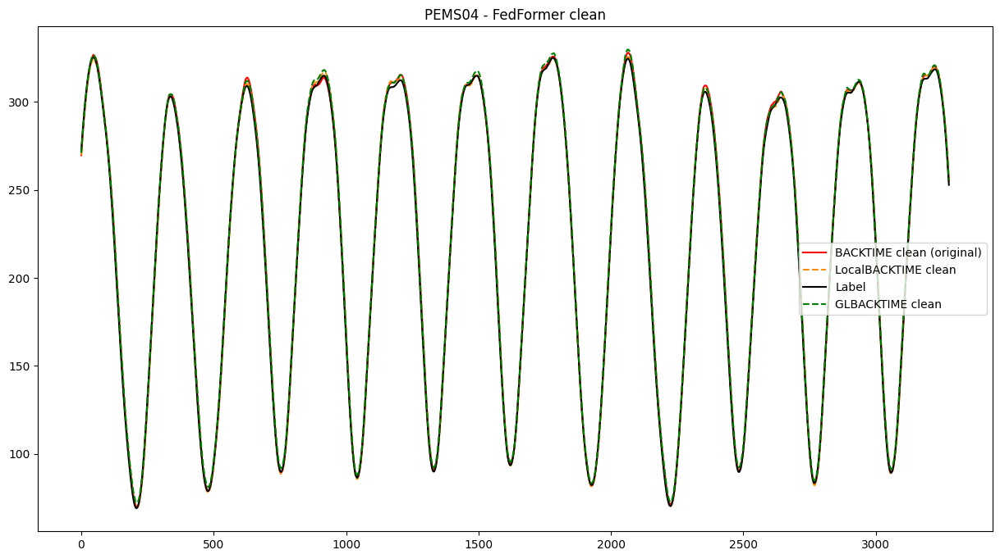

In [ ]:
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                           global_clean_label=global_clean_label, 
                           global_clean_prediction=global_clean_prediction, 
                           local_atk_prediction=local_atk_prediction, 
                           local_clean_prediction=local_clean_prediction,
                           global_local_atk_prediction=global_local_atk_prediction,
                           global_local_clean_prediction=global_local_clean_prediction,
                           title="PEMS04 - FedFormer clean",
                           mode = 'clean')

# PESM08

In [73]:
dataset_name = "PEMS08"
data_config = edict(config['Dataset'][dataset_name])

if not data_config.use_timestamps:
    train_mean, train_std, train_data_seq, test_data_seq = load_raw_data(data_config)
    train_data_stamps = test_data_stamps = None

In [74]:
import einops
print(train_data_seq.shape, test_data_seq.shape)
transformed_train_data_seq = einops.rearrange(train_data_seq, "b c t -> b (c t)")
transformed_test_data_seq = einops.rearrange(test_data_seq, "b c t -> b (c t)")
transformed_train_data_seq.mean(axis=1).shape, transformed_test_data_seq.mean(axis=1).shape

(10713, 170, 3) (3572, 170, 3)


((10713,), (3572,))

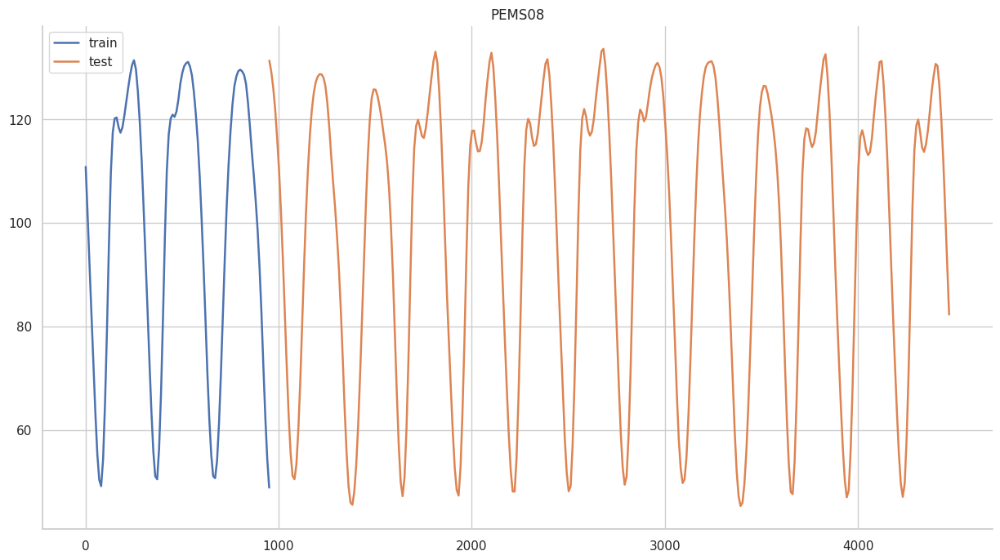

In [ ]:
train_mean = transformed_train_data_seq.mean(axis=1).tolist()
test_mean  = transformed_test_data_seq.mean(axis=1).tolist()

y_train = train_mean[-1000:]
y_test  = test_mean

import numpy as np
import matplotlib.pyplot as plt

def moving_avg(arr, window):
    arr = np.asarray(arr)
    if window <= 1:
        return arr
    # simple convolution moving average
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode='valid')

window = 50   # smooth over 50 timesteps (tune)
stride = 10   # plot every 10th smoothed point (tune)

y_train_smooth = moving_avg(y_train, window)
y_test_smooth  = moving_avg(y_test, window)

x_train_s = np.arange(1, len(y_train_smooth)+1)[::stride]
x_test_s  = np.arange(len(y_train_smooth)+1, len(y_train_smooth)+1 + len(y_test_smooth))[::stride]

plt.figure(figsize=(15, 8))
plt.title("PEMS08")
plt.plot(x_train_s, y_train_smooth[::stride], label='train', linewidth=1.8)
plt.plot(x_test_s,  y_test_smooth[::stride],  label='test', linewidth=1.8)
plt.legend()
plt.show()


## TimesNet

In [75]:
df_global_timesnet_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_TimesNet_TimesNet/PEMS08_cone_trigger=TgrGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

df_local_timesnet_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_TimesNet_TimesNet/PEMS08_cone_trigger=TgrCNN1D_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")

df_global_local_timesnet_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrHybridGCN_TimesNet_TimesNet/PEMS08_cone_trigger=TgrHybridGCN_surrogate=TimesNet_model=TimesNet_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")

print("Global Clean MAE", df_global_timesnet_pems08[df_global_timesnet_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_timesnet_pems08[df_global_timesnet_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_timesnet_pems08[df_local_timesnet_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_timesnet_pems08[df_local_timesnet_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_timesnet_pems08[df_global_local_timesnet_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_timesnet_pems08[df_global_local_timesnet_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 24.08087921142578
Global ATK MAE 26.63428497314453
Local Clean MAE 24.823383331298828
Local ATK MAE 28.043991088867188
Global Local Clean MAE 23.90841484069824
Global Local ATK MAE 26.02558898925781


## FedFormer

In [76]:
df_global_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_FEDformer_FEDformer/PEMS08_cone_trigger=TgrGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")

df_local_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_FEDformer_FEDformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=-1_test_metrics.csv")

df_global_local_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrHybridGCN_FEDformer_FEDformer/PEMS08_cone_trigger=TgrHybridGCN_surrogate=FEDformer_model=FEDformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=10__feature_alpha=0.75_test_metrics.csv")

print("Global Clean MAE", df_global_fedformer_pems08[df_global_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_fedformer_pems08[df_global_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_fedformer_pems08[df_local_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_fedformer_pems08[df_local_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_fedformer_pems08[df_global_local_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_fedformer_pems08[df_global_local_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 17.863054275512695
Global ATK MAE 10.56631565093994
Local Clean MAE 18.22810173034668
Local ATK MAE 12.77785873413086
Global Local Clean MAE 18.551008224487305
Global Local ATK MAE 13.88963794708252


## Autoformer

In [77]:
df_global_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_test_metrics.csv")
df_local_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_Autoformer_Autoformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_test_metrics.csv")
df_global_local_fedformer_pems08 = pd.read_csv("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_test_metrics.csv")
print("Global Clean MAE", df_global_fedformer_pems08[df_global_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global ATK MAE", df_global_fedformer_pems08[df_global_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Local Clean MAE", df_local_fedformer_pems08[df_local_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Local ATK MAE", df_local_fedformer_pems08[df_local_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])
print("Global Local Clean MAE", df_global_local_fedformer_pems08[df_global_local_fedformer_pems08['phase'] == 'victim']['clean_mae'].tolist()[-1])
print("Global Local ATK MAE", df_global_local_fedformer_pems08[df_global_local_fedformer_pems08['phase'] == 'victim']['attacked_mae'].tolist()[-1])


Global Clean MAE 18.793556213378903
Global ATK MAE 18.06523704528809
Local Clean MAE 18.808324813842773
Local ATK MAE 21.271114349365234
Global Local Clean MAE 18.9710750579834
Global Local ATK MAE 15.967683792114258


### Quantitative results

#### Autoformer

In [78]:
global_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_199.npy")

global_atk_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=64_warmup=10__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_199.npy")

global_clean_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_targets_epoch99_victim_180.npy")

global_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_180.npy")
print("PEMS08: global atk, label, clean prediction, clean label", global_atk_prediction.shape, global_atk_label.shape, global_clean_prediction.shape, global_clean_label.shape)
global_atk_prediction = einops.rearrange(global_atk_prediction, "b c t -> b (c t)")
global_atk_label = einops.rearrange(global_atk_label, "b c t -> b (c t)")
global_clean_label = einops.rearrange(global_clean_label, "b c t -> b (c t)")
global_clean_prediction = einops.rearrange(global_clean_prediction, "b c t -> b (c t)")

print("PEMS08: global atk, label, clean prediction, clean label", global_atk_prediction.shape, global_atk_label.shape, global_clean_prediction.shape, global_clean_label.shape)

PEMS08: global atk, label, clean prediction, clean label (3549, 7, 51) (3549, 7, 51) (3549, 12, 170) (3549, 12, 170)
PEMS08: global atk, label, clean prediction, clean label (3549, 357) (3549, 357) (3549, 2040) (3549, 2040)


In [79]:
# local_clean_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_Autoformer_Autoformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_targets_epoch99_victim_180.npy")
# local_clean_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_Autoformer_Autoformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/clean_predictions_epoch99_victim_180.npy")
local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_Autoformer_Autoformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_predictions_epoch99_victim_180.npy")
local_atk_label = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrCNN1D_Autoformer_Autoformer/PEMS08_cone_trigger=TgrCNN1D_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=-1_arrays/attacked_targets_epoch99_victim_180.npy")
print(local_atk_prediction.shape)
print(local_atk_label.shape)
print("PEMS08: local atk, label, clean prediction, clean label", local_atk_prediction.shape, local_atk_label.shape)
local_atk_prediction = einops.rearrange(local_atk_prediction, "b c t -> b (c t)")
local_atk_label = einops.rearrange(local_atk_label, "b c t -> b (c t)")
local_atk_prediction.shape, local_atk_label.shape 


(3549, 7, 51)
(3549, 7, 51)
PEMS08: local atk, label, clean prediction, clean label (3549, 7, 51) (3549, 7, 51)


((3549, 357), (3549, 357))

In [80]:
global_local_atk_prediction = np.load("/home/tanpham/BadFedBacktime/log_results/PEMS08_cone_TgrHybridGCN_Autoformer_Autoformer/PEMS08_cone_trigger=TgrHybridGCN_surrogate=Autoformer_model=Autoformer_trigger_len=4_pattern_len=7_beftgrlen=6_lamnorm=0.05_alphas=0.3_alphat=0.03_epsilon=0.2_hiddendim=16_warmup=50__feature_alpha=0.75_arrays/attacked_predictions_epoch99_victim_180.npy")
print(global_local_atk_prediction.shape)
global_local_atk_prediction = einops.rearrange(global_local_atk_prediction, "b c t -> b (c t)")
global_local_atk_prediction.shape


(3549, 7, 51)


(3549, 357)

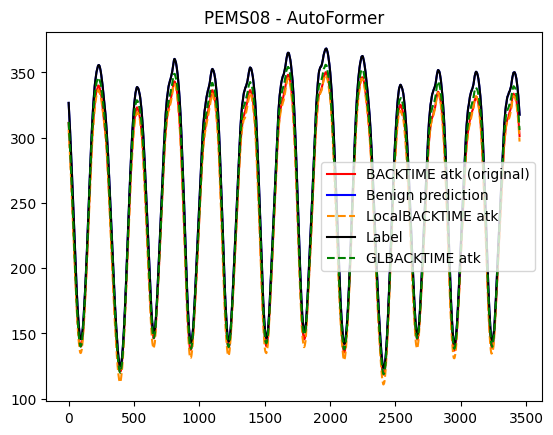

In [ ]:
visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                            global_atk_label=global_atk_label,
                            global_clean_label=global_clean_label, 
                            global_clean_prediction=global_clean_prediction, 
                            local_atk_prediction=local_atk_prediction, 
                            local_clean_prediction=local_clean_prediction,
                            global_local_atk_prediction=global_local_atk_prediction,
                            global_local_clean_prediction=global_local_clean_prediction,
                            title="PEMS08 - AutoFormer",
                            mode = 'atk')

<Figure size 640x480 with 0 Axes>

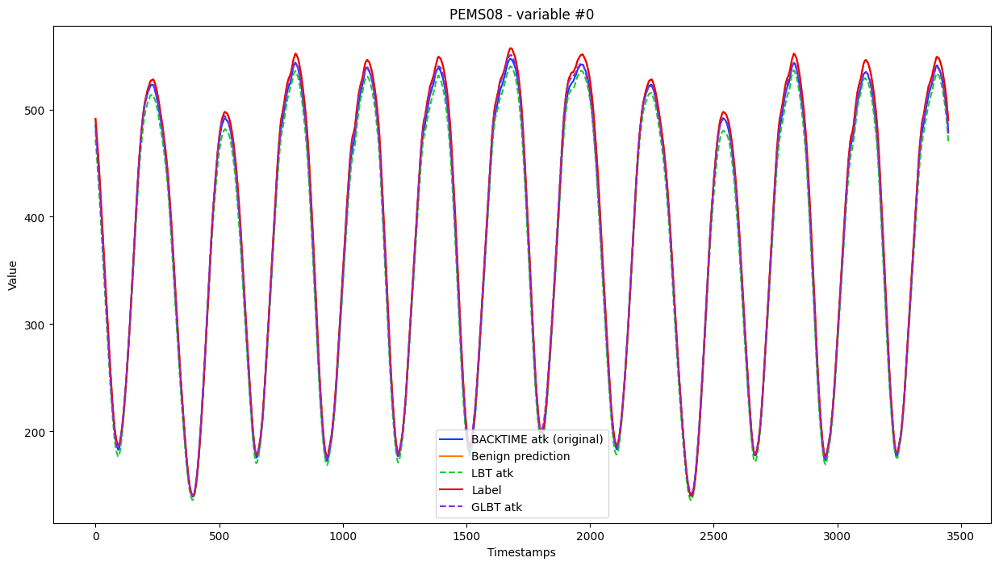

<Figure size 640x480 with 0 Axes>

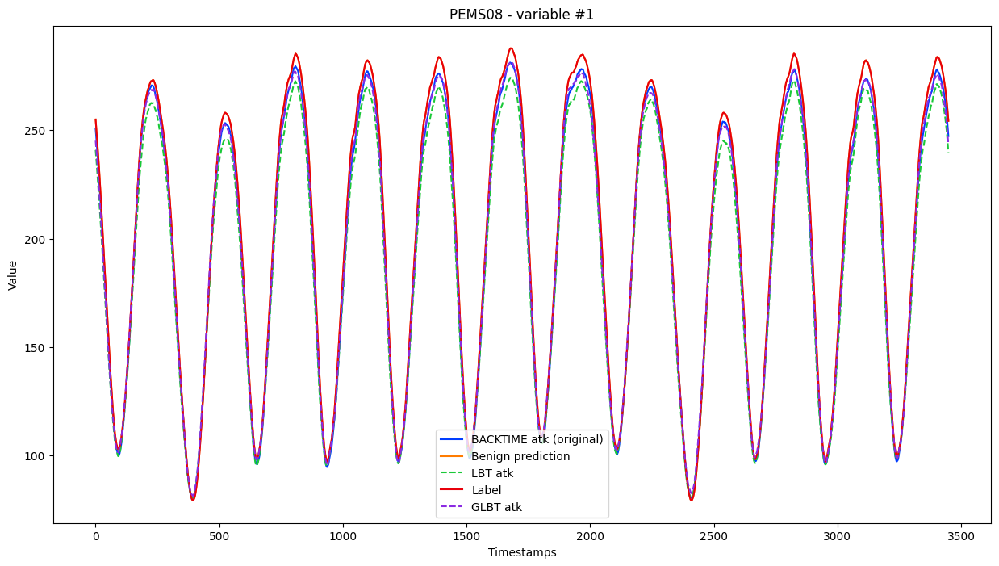

<Figure size 640x480 with 0 Axes>

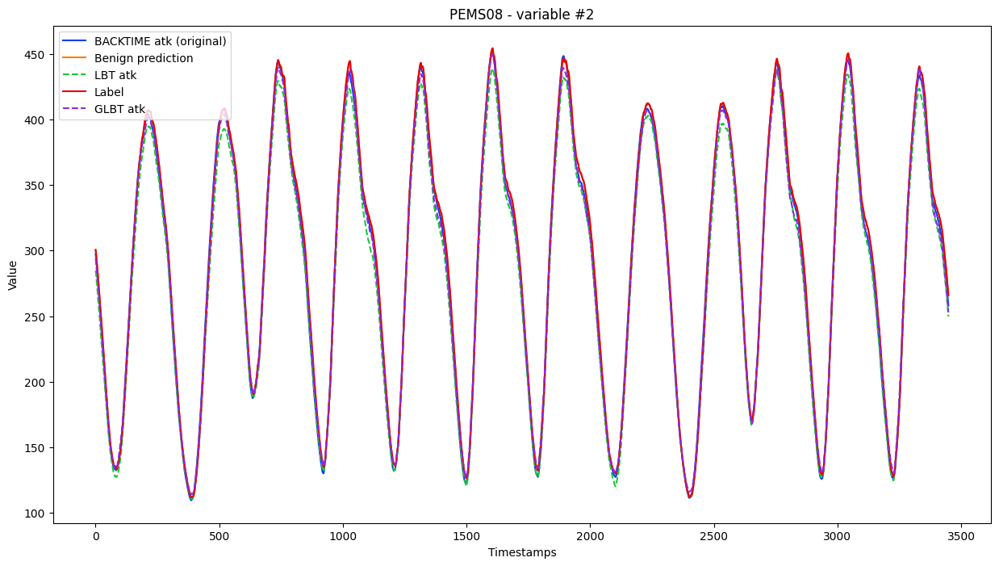

<Figure size 640x480 with 0 Axes>

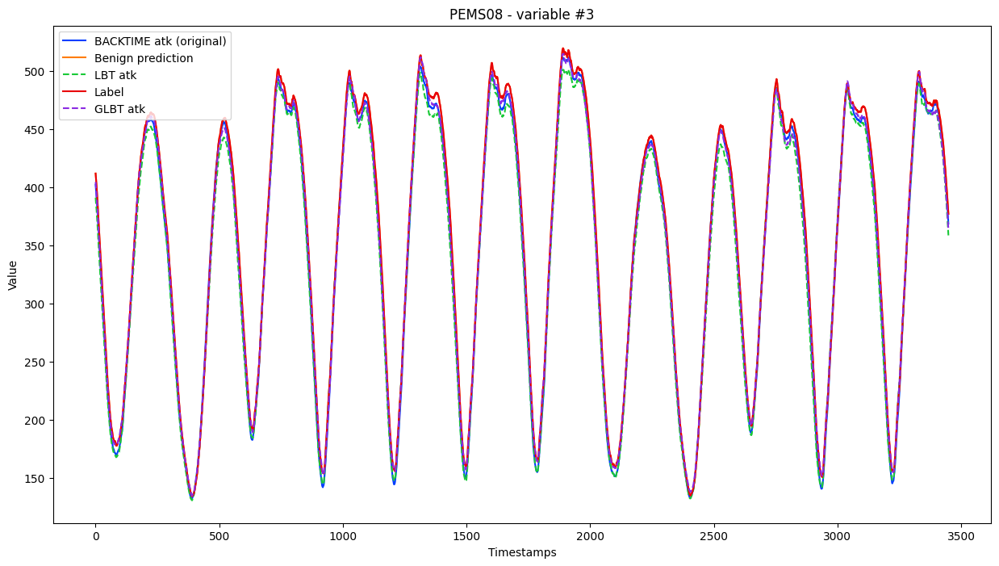

<Figure size 640x480 with 0 Axes>

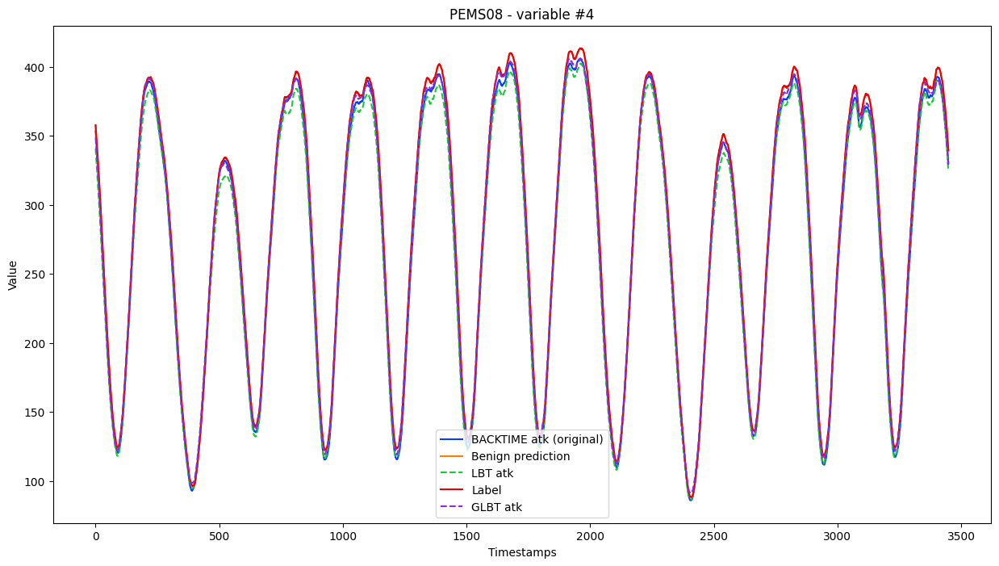

<Figure size 640x480 with 0 Axes>

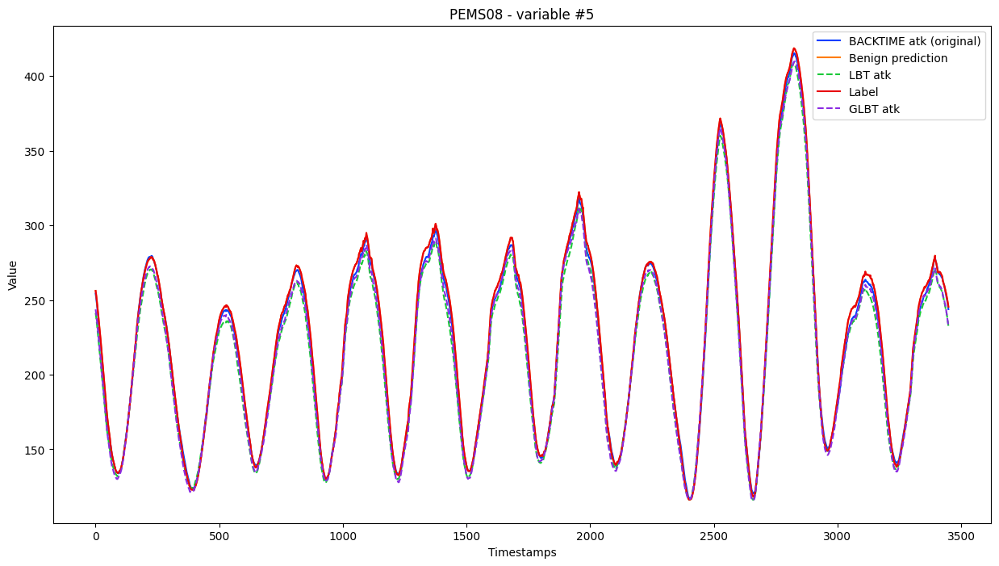

<Figure size 640x480 with 0 Axes>

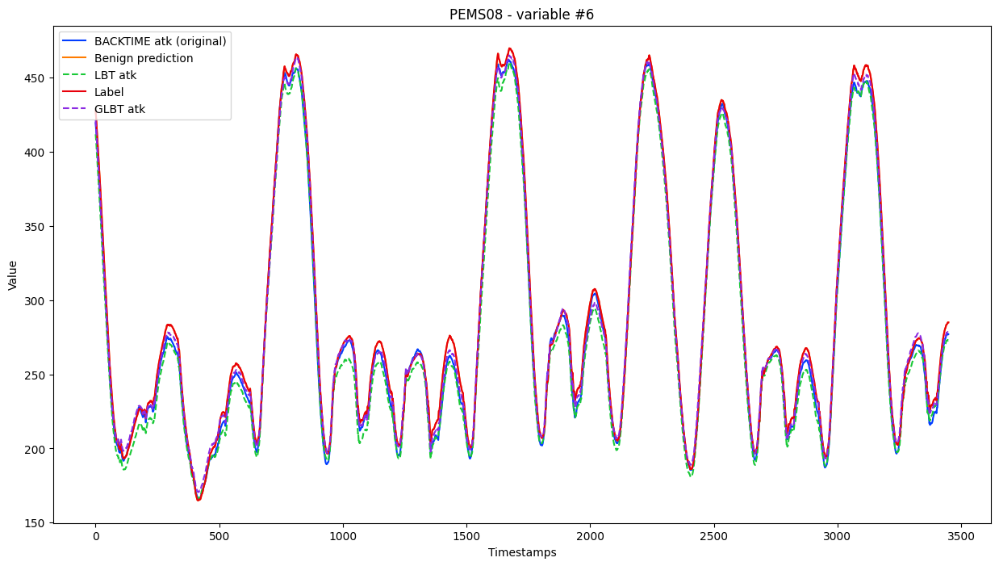

<Figure size 640x480 with 0 Axes>

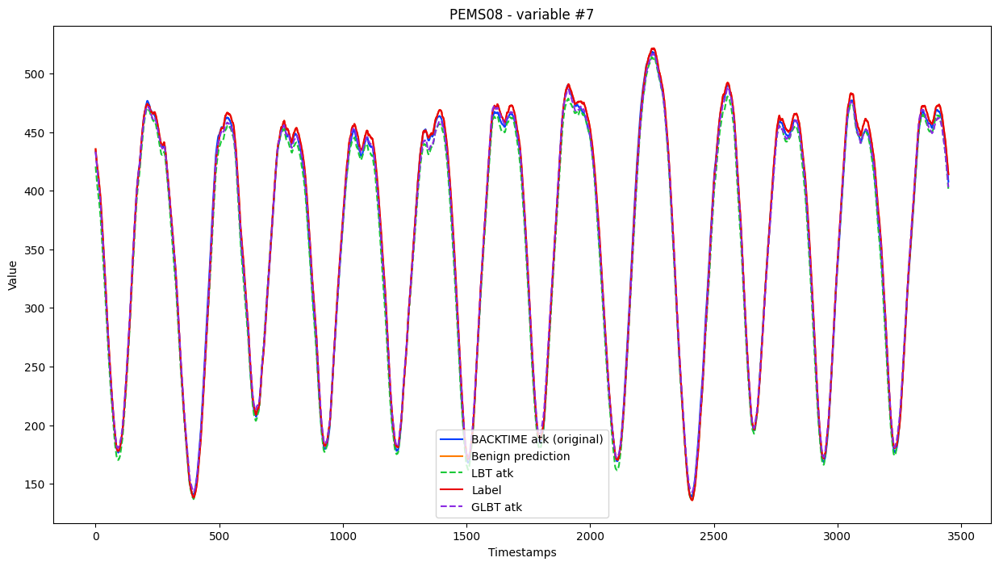

<Figure size 640x480 with 0 Axes>

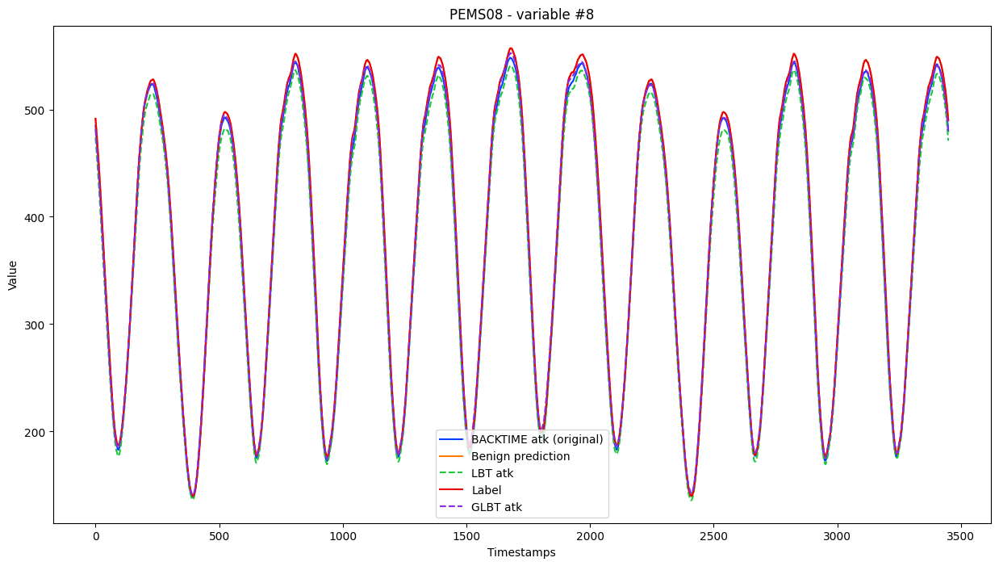

<Figure size 640x480 with 0 Axes>

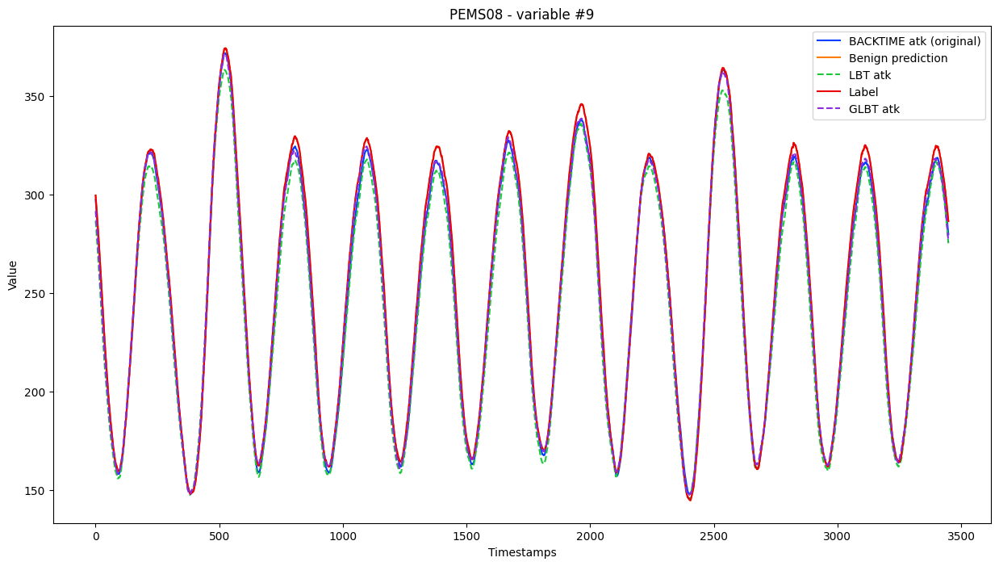

<Figure size 640x480 with 0 Axes>

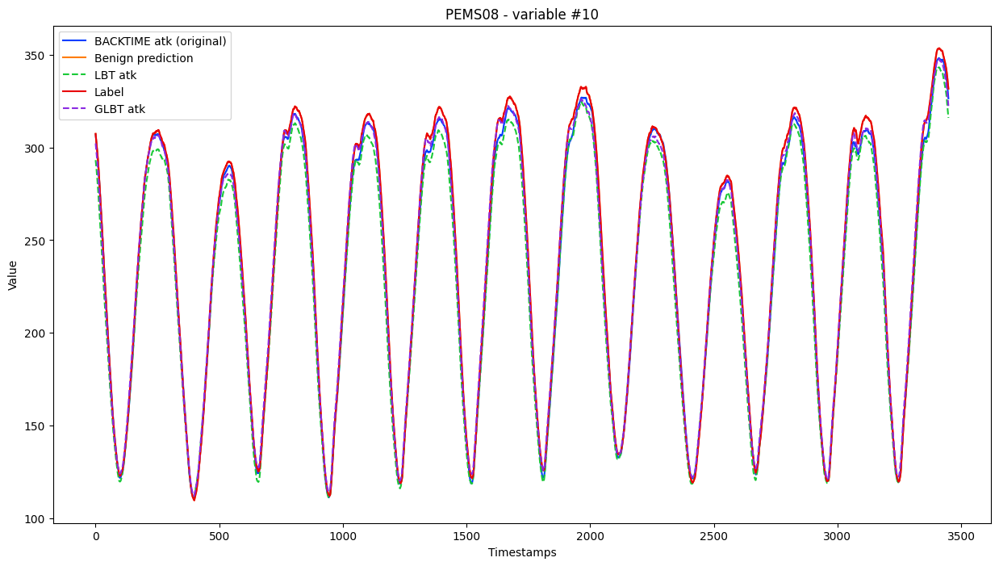

<Figure size 640x480 with 0 Axes>

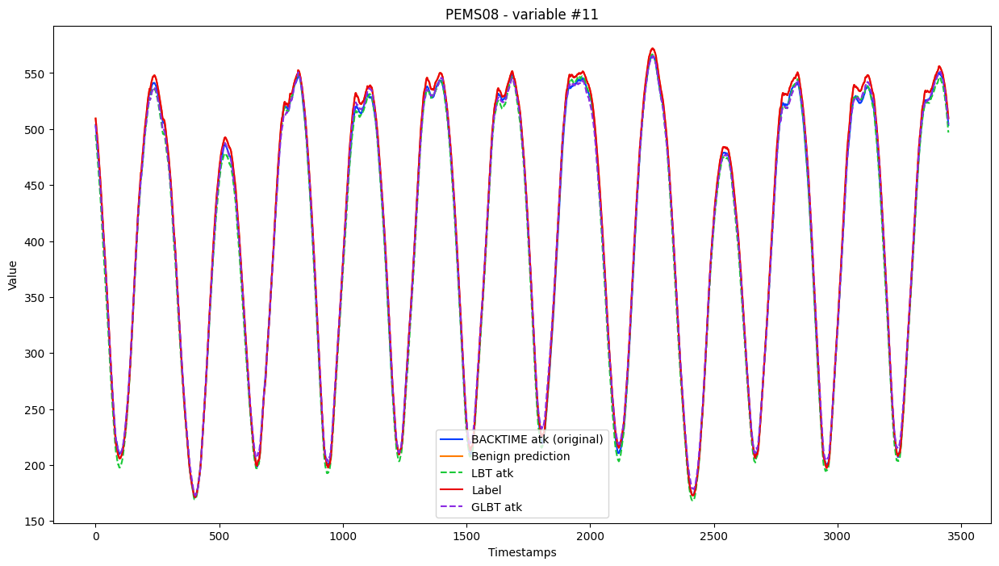

IndexError: index 12 is out of bounds for axis 1 with size 12

In [81]:
for feature_id in range(global_atk_prediction.shape[1]):
    mini_visualize_backdoor_pattern(global_atk_prediction=global_atk_prediction, 
                            global_atk_label=global_atk_label,
                            global_clean_label=global_clean_label, 
                            global_clean_prediction=global_clean_prediction, 
                            local_atk_prediction=local_atk_prediction, 
                            local_clean_prediction=local_clean_prediction,
                            global_local_atk_prediction=global_local_atk_prediction,
                            global_local_clean_prediction=global_local_clean_prediction,
                            title="PEMS08 - variable #" + str(feature_id),
                            feature_id=feature_id,
                            mode = 'atk')

# Transfer learning

## Fedformer -> TimesNet (cone)

In [ ]:
global_atk_mae = pd.read_csv("")

(23.034473419189453, 24.734886169433597)